In [5]:
import itertools
import librosa
import os
import pywt
import torch

import numpy as np
import pandas as pd
import torch.nn as nn

from matplotlib.colors import TwoSlopeNorm
import matplotlib.pyplot as plt
from scipy.signal import freqz

from deepfake.cnn import CustomCNN, WaveletPooling
from deepfake.constants import WAVELET_FAMILIES
from deepfake.data import frequency_ordered_nodes
from deepfake.features import reconstruct_node

In [6]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
results_dir = "results/train_all"
seed = 42

In [7]:
audios = np.load("./datasets/waveforms/dev_2019.npy")
meta = pd.read_csv("./datasets/waveforms/dev_2019_meta.csv")

In [8]:
nodes = frequency_ordered_nodes(3)

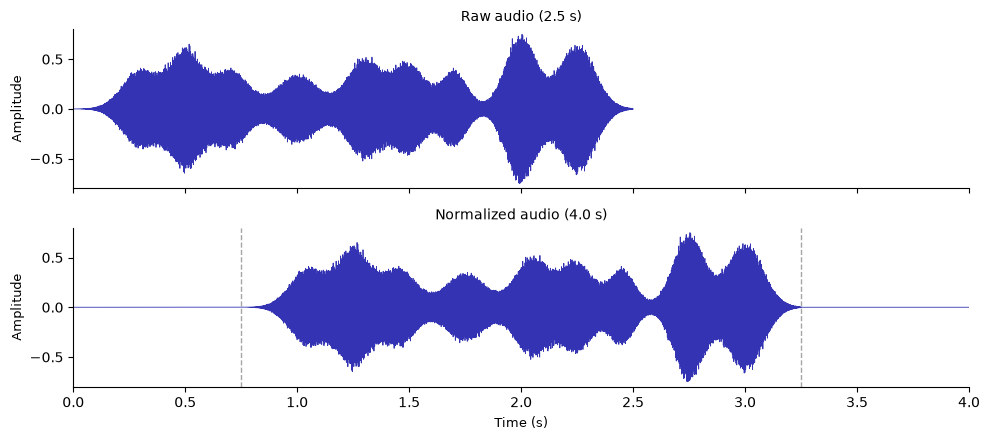

In [10]:
# AI-generated code.
# Synthetic audio simulating human speech and preprocessing steps for the model.

sr = 16000
duration = 2.5 
t_raw = np.linspace(0, duration, int(sr * duration), endpoint=False)


carrier = np.sin(2 * np.pi * 300 * t_raw) + 0.5 * np.sin(2 * np.pi * 600 * t_raw)
noise = np.random.normal(0, 0.1, size=len(t_raw))
signal_base = (carrier + noise)

burst_centers = [0.3, 0.5, 0.7, 1.0, 1.3, 1.5, 1.7, 2.0, 2.25]
burst_widths  = [0.08, 0.07, 0.08, 0.09, 0.08, 0.07, 0.06, 0.07, 0.08]
burst_heights = [0.4,  0.6,  0.4,  0.35, 0.5,  0.45, 0.38, 0.75, 0.65]

envelope = np.zeros_like(t_raw)
for c, w, h in zip(burst_centers, burst_widths, burst_heights):
    envelope += h * np.exp(-((t_raw - c) ** 2) / (2 * w ** 2))

y_raw = signal_base * envelope
y_raw = y_raw / np.max(np.abs(y_raw)) * 0.75

target_duration = 4.0
target_length = int(target_duration * sr)

current_length = len(y_raw)
total_padding = target_length - current_length

pad_left = total_padding // 2
pad_right = total_padding - pad_left

y_padded = np.pad(y_raw, (pad_left, pad_right), mode='constant', constant_values=0.0)
t_padded = np.linspace(0, target_duration, len(y_padded), endpoint=False)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 4.5), sharex=True)

line_color = '#3333b3'

ax1.plot(t_raw, y_raw, color=line_color, linewidth=0.6)
ax1.set_title(f'Raw audio ({duration} s)', fontsize=10)
ax1.set_ylabel('Amplitude', fontsize=9)
ax1.set_ylim(-0.8, 0.8)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

ax2.plot(t_padded, y_padded, color=line_color, linewidth=0.6)
ax2.set_title(f'Normalized audio ({target_duration} s)', fontsize=10)
ax2.set_ylabel('Amplitude', fontsize=9)
ax2.set_xlabel('Time (s)', fontsize=9)
ax2.set_ylim(-0.8, 0.8)
ax2.set_xlim(0.0, 4.0)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

start_time = pad_left / sr
end_time = start_time + duration
ax2.axvline(x=start_time, color='gray', linestyle='--', linewidth=1, alpha=0.7)
ax2.axvline(x=end_time, color='gray', linestyle='--', linewidth=1, alpha=0.7)

plt.tight_layout()
plt.show()

## Decomposition, Power and Frequency Plots

In [11]:
bonafide = meta[meta["is_bonafide"] == True][:1]
bonafide.index

RangeIndex(start=0, stop=1, step=1)

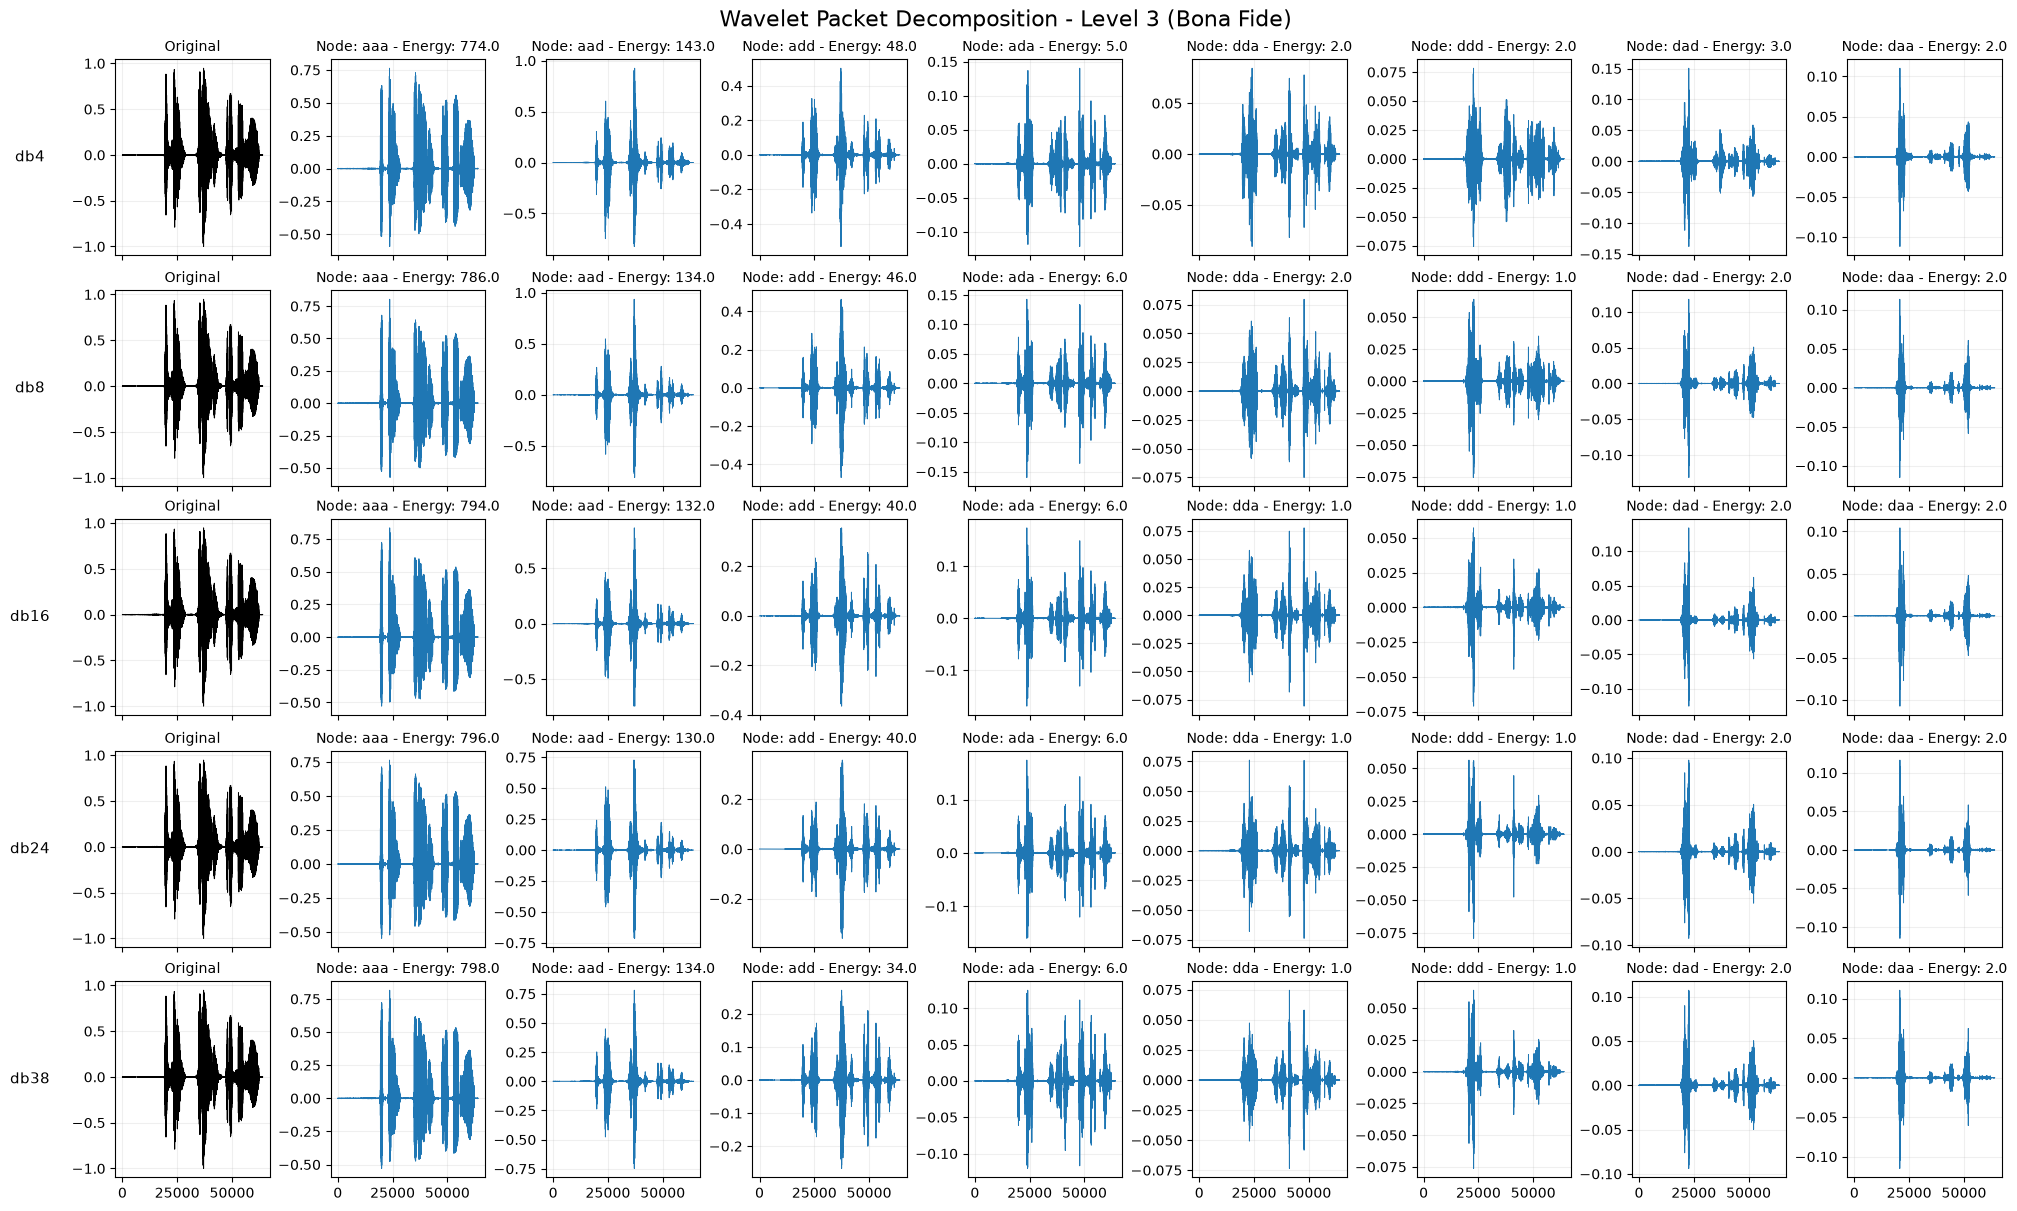

In [12]:
fig, axs = plt.subplots(
    len(WAVELET_FAMILIES),
    len(nodes) + 1,
    figsize=(20, 12),
    sharex=True,
    constrained_layout=True
)

original = torch.from_numpy((audios[bonafide.index].astype(np.float32) / 32768).squeeze())

for wave_idx, wavelet in enumerate(WAVELET_FAMILIES):

    axs[wave_idx, 0].plot(original, color="black", linewidth=0.7)
    axs[wave_idx, 0].set_title("Original", fontsize=10)

    for node_idx, node in enumerate(nodes):

        coeff = reconstruct_node(original, wavelet, 3, node)

        axs[wave_idx, node_idx + 1].plot(
            coeff,
            linewidth=0.7
        )

        axs[wave_idx, node_idx + 1].set_title(
            f"Node: {node} - Energy: {torch.round(torch.sum(torch.pow(coeff, 2)))}",
            fontsize=10
        )

    axs[wave_idx, 0].set_ylabel(
        wavelet,
        fontsize=11,
        rotation=0,
        labelpad=30,
        va="center"
    )

    for ax in axs[wave_idx]:
        ax.grid(alpha=0.2)

fig.suptitle(
    "Wavelet Packet Decomposition - Level 3 (Bona Fide)",
    fontsize=16
)

plt.show()

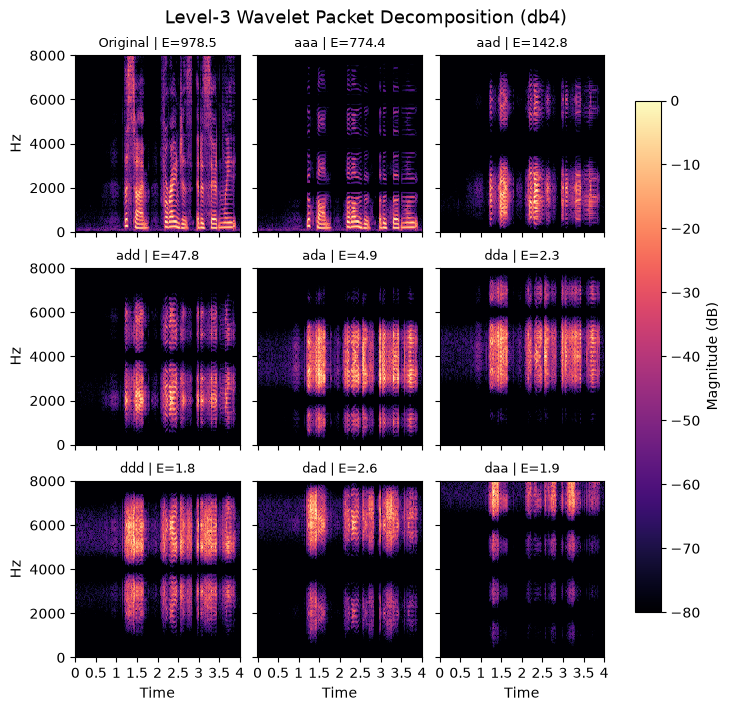

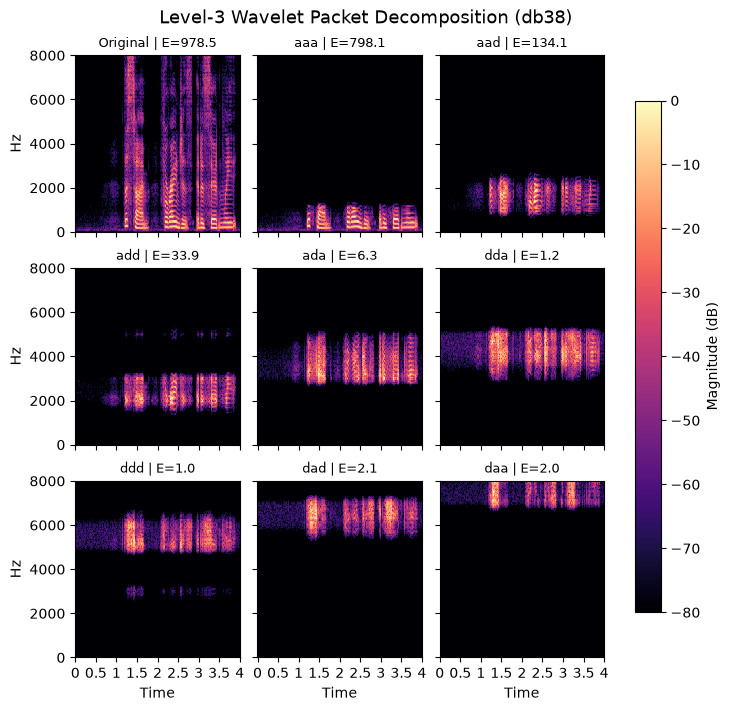

In [ ]:

WAVELETS_TO_PLOT = ["db4", "db38"]

fig, axs = plt.subplots(
    len(WAVELETS_TO_PLOT),
    len(nodes) + 1,
    figsize=(20, 6),
    sharex=True,
    sharey=True,
    constrained_layout=True
)

original = (
    audios[bonafide.index].astype(np.float32) / 32768
).squeeze()

D = librosa.stft(original, n_fft=512, hop_length=128)
S_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)

for wave_idx, wavelet in enumerate(WAVELETS_TO_PLOT):

    ax = axs[wave_idx, 0]

    img = librosa.display.specshow(
        S_db,
        y_axis="linear",
        x_axis="time",
        sr=16000,
        hop_length=128,
        cmap="magma",
        ax=ax
    )

    ax.set_title("Original", fontsize=10)

    for node_idx, node in enumerate(nodes):

        coeff = reconstruct_node(
            torch.from_numpy(original),
            wavelet,
            3,
            node
        )
        coeff = np.asarray(coeff).squeeze()

        D = librosa.stft(coeff, n_fft=512, hop_length=128)
        S_node = librosa.amplitude_to_db(
            np.abs(D),
            ref=np.max
        )

        ax = axs[wave_idx, node_idx + 1]

        img = librosa.display.specshow(
            S_node,
            y_axis="linear",
            x_axis="time",
            sr=16000,
            hop_length=128,
            cmap="magma",
            ax=ax
        )

        energy = np.sum(coeff ** 2)

        ax.set_title(
            f"{node}\nE: {energy:.0f}",
            fontsize=9
        )

    axs[wave_idx, 0].set_ylabel(
        wavelet,
        fontsize=12,
        rotation=0,
        labelpad=30,
        va="center"
    )

    for ax in axs[wave_idx]:
        ax.set_ylim(0, 8000)

fig.suptitle(
    "Level-3 Wavelet Packet Decomposition (Bona Fide)",
    fontsize=15
)

fig.colorbar(
    img,
    ax=axs,
    format="%+2.0f dB",
WAVELETS_TO_PLOT = ["db4", "db38"]

original = (
    audios[bonafide.index].astype(np.float32) / 32768
).squeeze()

for wavelet in WAVELETS_TO_PLOT:

    fig, axs = plt.subplots(
        3, 3,
        figsize=(7.2, 7.0),
        sharex=True,
        sharey=True,
        constrained_layout=True
    )

    signals = [original]
    titles = ["Original"]

    for node in nodes:
        coeff = reconstruct_node(
            torch.from_numpy(original),
            wavelet,
            3,
            node
        )
        coeff = np.asarray(coeff).squeeze()

        signals.append(coeff)
        titles.append(node)

    specs = []

    for signal in signals:
        D = librosa.stft(
            signal,
            n_fft=512,
            hop_length=128
        )

        S_db = librosa.amplitude_to_db(
            np.abs(D),
            ref=np.max
        )

        specs.append(S_db)

    for i, (signal, S_db, title) in enumerate(
        zip(signals, specs, titles)
    ):

        ax = axs.flat[i]

        img = librosa.display.specshow(
            S_db,
            sr=16000,
            hop_length=128,
            x_axis="time",
            y_axis="linear",
            cmap="magma",
            ax=ax
        )

        energy = np.sum(signal ** 2)

        ax.set_title(
            f"{title} | E={energy:.1f}",
            fontsize=9
        )

        ax.set_ylim(0, 8000)

        if i % 3 != 0:
            ax.set_ylabel("")

        if i < 6:
            ax.set_xlabel("")

    fig.suptitle(
        f"Level-3 Wavelet Packet Decomposition ({wavelet})",
        fontsize=13
    )

    fig.colorbar(
        img,
        ax=axs,
        label="Magnitude (dB)",
        shrink=0.85
    )

    fig.savefig(
        f"spectrogram_{wavelet}.pdf",
        bbox_inches="tight"
    )

    plt.show()

    label="Magnitude (dB)"
)

plt.show()


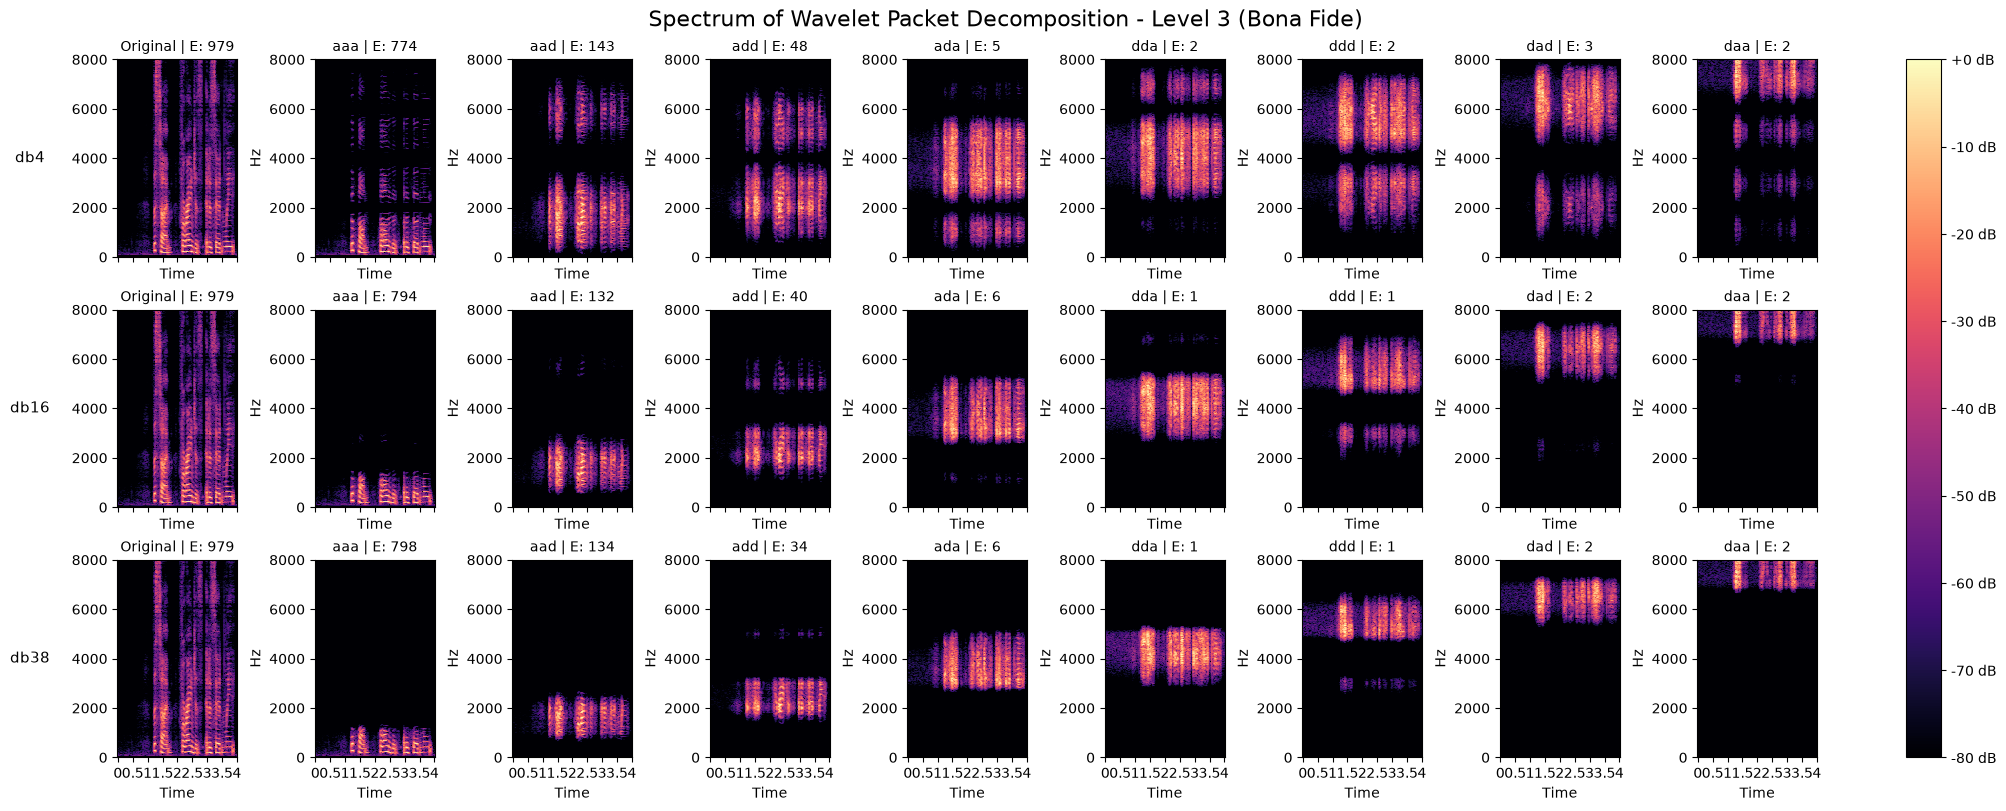

In [31]:
plot_wavelets = ["db4", "db16", "db38"]

fig, axs = plt.subplots(
    len(plot_wavelets),
    len(nodes) + 1,
    figsize=(20, 8),
    sharex=True,
    constrained_layout=True
)

original = (audios[bonafide.index].astype(np.float32) / 32768).squeeze()

for wave_idx, wavelet in enumerate(plot_wavelets):

    D = librosa.stft(original)
    S_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)

    ax = axs[wave_idx, 0]
    img = librosa.display.specshow(
        S_db,
        y_axis="linear",
        x_axis="time",
        sr=16000,
        ax=ax
    )

    energy = np.sum(original ** 2)
    ax.set_title(f"Original | E: {energy:.0f}", fontsize=10)

    for node_idx, node in enumerate(nodes):

        coeff = reconstruct_node(torch.from_numpy(original), wavelet, 3, node)
        coeff = np.asarray(coeff)

        D = librosa.stft(coeff)
        S_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)

        ax = axs[wave_idx, node_idx + 1]
        img = librosa.display.specshow(
            S_db,
            y_axis="linear",
            x_axis="time",
            sr=16000,
            ax=ax
        )
        energy = np.sum(coeff ** 2)
        ax.set_title(
            f"{node} | E: {energy:.0f}",
            fontsize=10
        )

    axs[wave_idx, 0].set_ylabel(
        wavelet,
        fontsize=11,
        rotation=0,
        labelpad=30,
        va="center"
    )

fig.suptitle(
    "Spectrum of Wavelet Packet Decomposition - Level 3 (Bona Fide)",
    fontsize=16
)
fig.colorbar(img, ax=axs, format="%+2.0f dB")

plt.show()

In [9]:
spoof = meta[meta["is_bonafide"] == False][:1]
spoof.index

RangeIndex(start=2548, stop=2549, step=1)

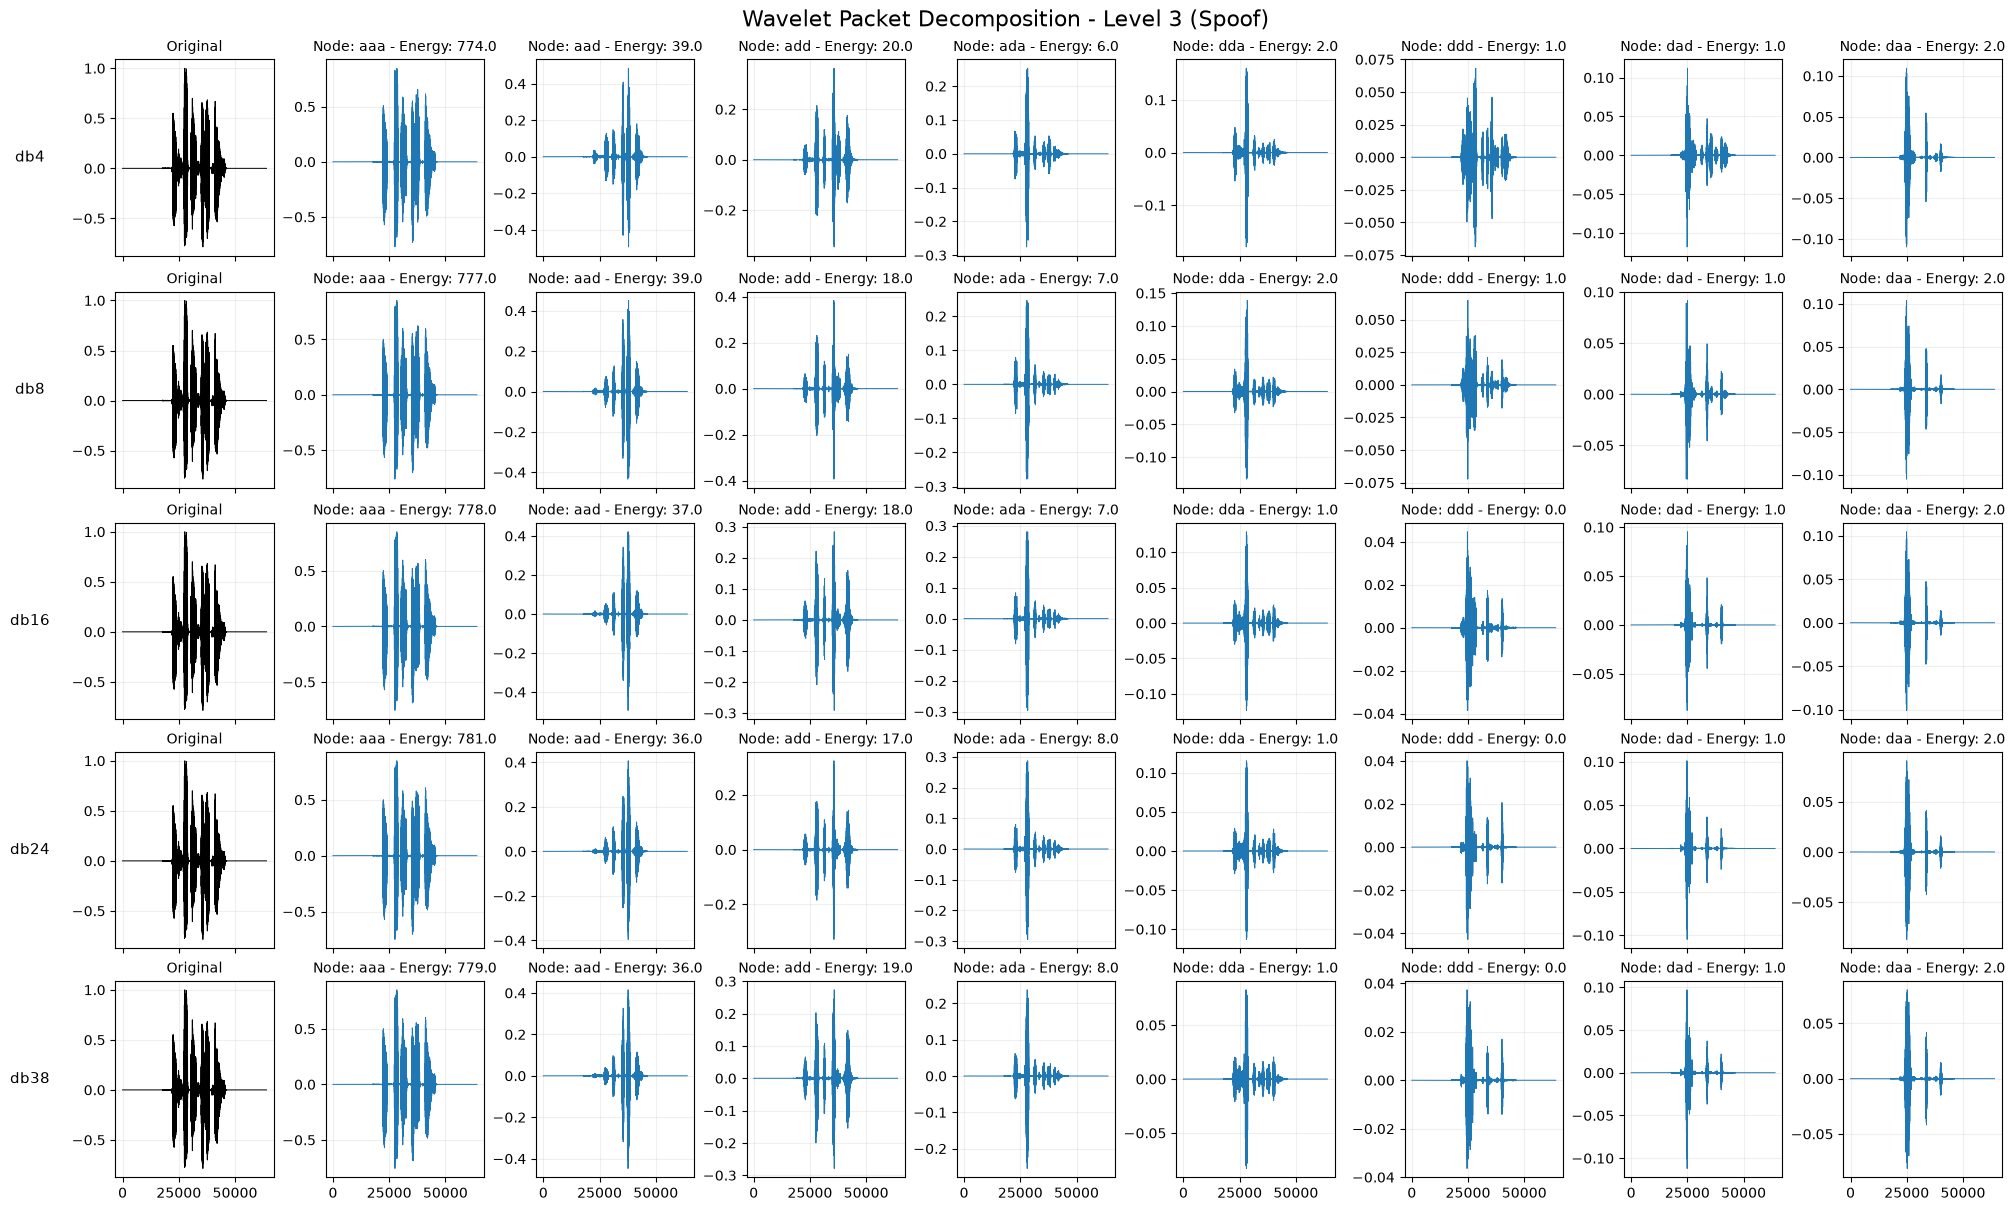

In [10]:
fig, axs = plt.subplots(
    len(WAVELET_FAMILIES),
    len(nodes) + 1,
    figsize=(20, 12),
    sharex=True,
    constrained_layout=True
)

original = (audios[spoof.index].astype(np.float32) / 32768).squeeze()

for wave_idx, wavelet in enumerate(WAVELET_FAMILIES):

    axs[wave_idx, 0].plot(original, color="black", linewidth=0.7)
    axs[wave_idx, 0].set_title("Original", fontsize=10)

    for node_idx, node in enumerate(nodes):

        coeff = reconstruct_node(torch.from_numpy(original), wavelet, 3, node)

        axs[wave_idx, node_idx + 1].plot(
            coeff,
            linewidth=0.7
        )

        axs[wave_idx, node_idx + 1].set_title(
            f"Node: {node} - Energy: {torch.round(torch.sum(torch.pow(coeff, 2)))}",
            fontsize=10
        )

    axs[wave_idx, 0].set_ylabel(
        wavelet,
        fontsize=11,
        rotation=0,
        labelpad=30,
        va="center"
    )

    for ax in axs[wave_idx]:
        ax.grid(alpha=0.2)

fig.suptitle(
    "Wavelet Packet Decomposition - Level 3 (Spoof)",
    fontsize=16
)

plt.show()

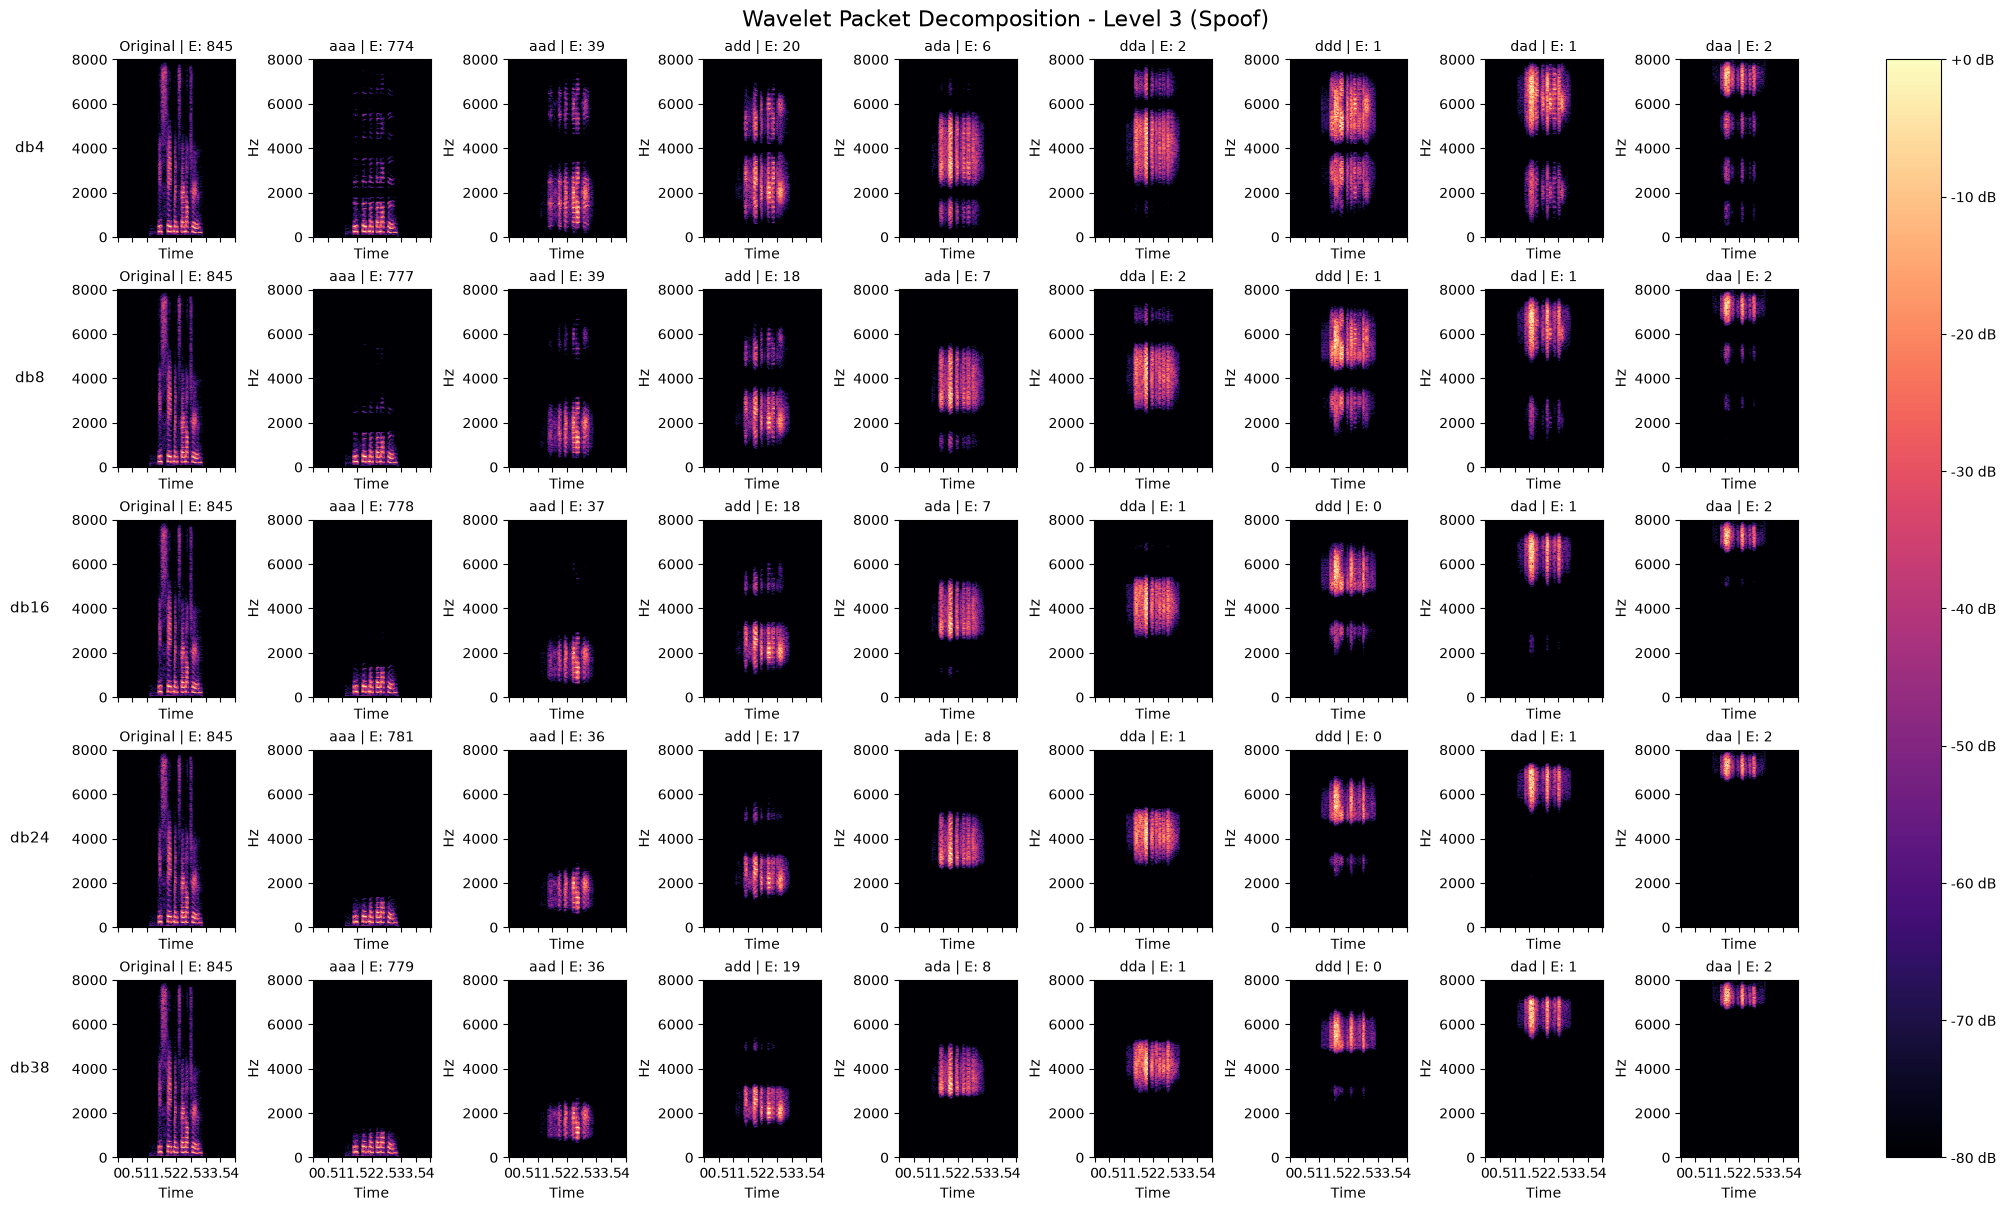

In [11]:
fig, axs = plt.subplots(
    len(WAVELET_FAMILIES),
    len(nodes) + 1,
    figsize=(20, 12),
    sharex=True,
    constrained_layout=True
)

original = (audios[spoof.index].astype(np.float32) / 32768).squeeze()

for wave_idx, wavelet in enumerate(WAVELET_FAMILIES):

    # Original
    D = librosa.stft(original)
    S_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)

    ax = axs[wave_idx, 0]
    img = librosa.display.specshow(
        S_db,
        y_axis="linear",
        x_axis="time",
        sr=16000,
        ax=ax
    )
    energy = np.sum(original ** 2)
    ax.set_title(f"Original | E: {energy:.0f}", fontsize=10)

    for node_idx, node in enumerate(nodes):

        coeff = reconstruct_node(torch.from_numpy(original), wavelet, 3, node)
        coeff = np.asarray(coeff)

        D = librosa.stft(coeff)
        S_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)

        ax = axs[wave_idx, node_idx + 1]
        img = librosa.display.specshow(
            S_db,
            y_axis="linear",
            x_axis="time",
            sr=16000,
            ax=ax
        )
        energy = np.sum(coeff ** 2)
        ax.set_title(
            f"{node} | E: {energy:.0f}",
            fontsize=10
        )

    axs[wave_idx, 0].set_ylabel(
        wavelet,
        fontsize=11,
        rotation=0,
        labelpad=30,
        va="center"
    )

fig.suptitle(
    "Wavelet Packet Decomposition - Level 3 (Spoof)",
    fontsize=16
)
fig.colorbar(img, ax=axs, format="%+2.0f dB")

plt.show()

## Wavelet and Filters Plots

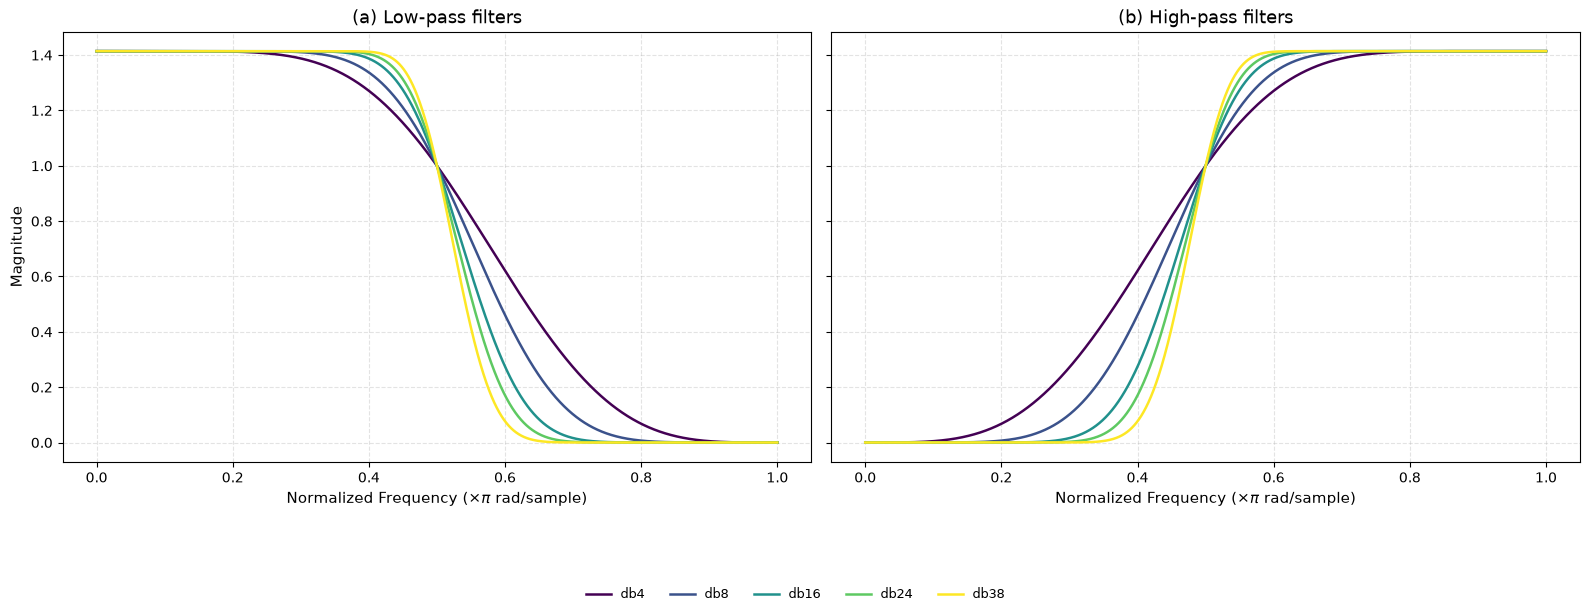

In [ ]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 6),
    sharey=True
)

num_colors = len(WAVELET_FAMILIES)
colors = plt.cm.viridis(np.linspace(0, 1, num_colors))

for idx, wavelet in enumerate(WAVELET_FAMILIES):

    w = pywt.Wavelet(wavelet)
    color = colors[idx]

    # Low-pass
    db_filter = w.filter_bank[0]
    w_db, h_db = freqz(db_filter, worN=16000)
    freq_db = w_db / np.pi

    axes[0].plot(
        freq_db,
        np.abs(h_db),
        linewidth=1.8,
        color=color,
        label=wavelet
    )

    # High-pass
    db_filter = w.filter_bank[1]
    w_db, h_db = freqz(db_filter, worN=16000)
    freq_db = w_db / np.pi

    axes[1].plot(
        freq_db,
        np.abs(h_db),
        linewidth=1.8,
        color=color,
        label=wavelet
    )

axes[0].set_title("(a) Low-pass filters", fontsize=13)
axes[1].set_title("(b) High-pass filters", fontsize=13)

for ax in axes:
    ax.set_xlabel("Normalized Frequency ($\\times\\pi$ rad/sample)", fontsize=11)
    ax.grid(True, linestyle="--", alpha=0.35)

axes[0].set_ylabel("Magnitude", fontsize=11)

# Legenda compartilhada
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=10,
    fontsize=9,
    frameon=False,
    bbox_to_anchor=(0.5, -0.03)
)

plt.tight_layout(rect=[0, 0.12, 1, 1])

plt.savefig("daubechies_frequency_response.pdf", bbox_inches="tight")
plt.savefig("daubechies_frequency_response.png", dpi=400, bbox_inches="tight")

plt.show()


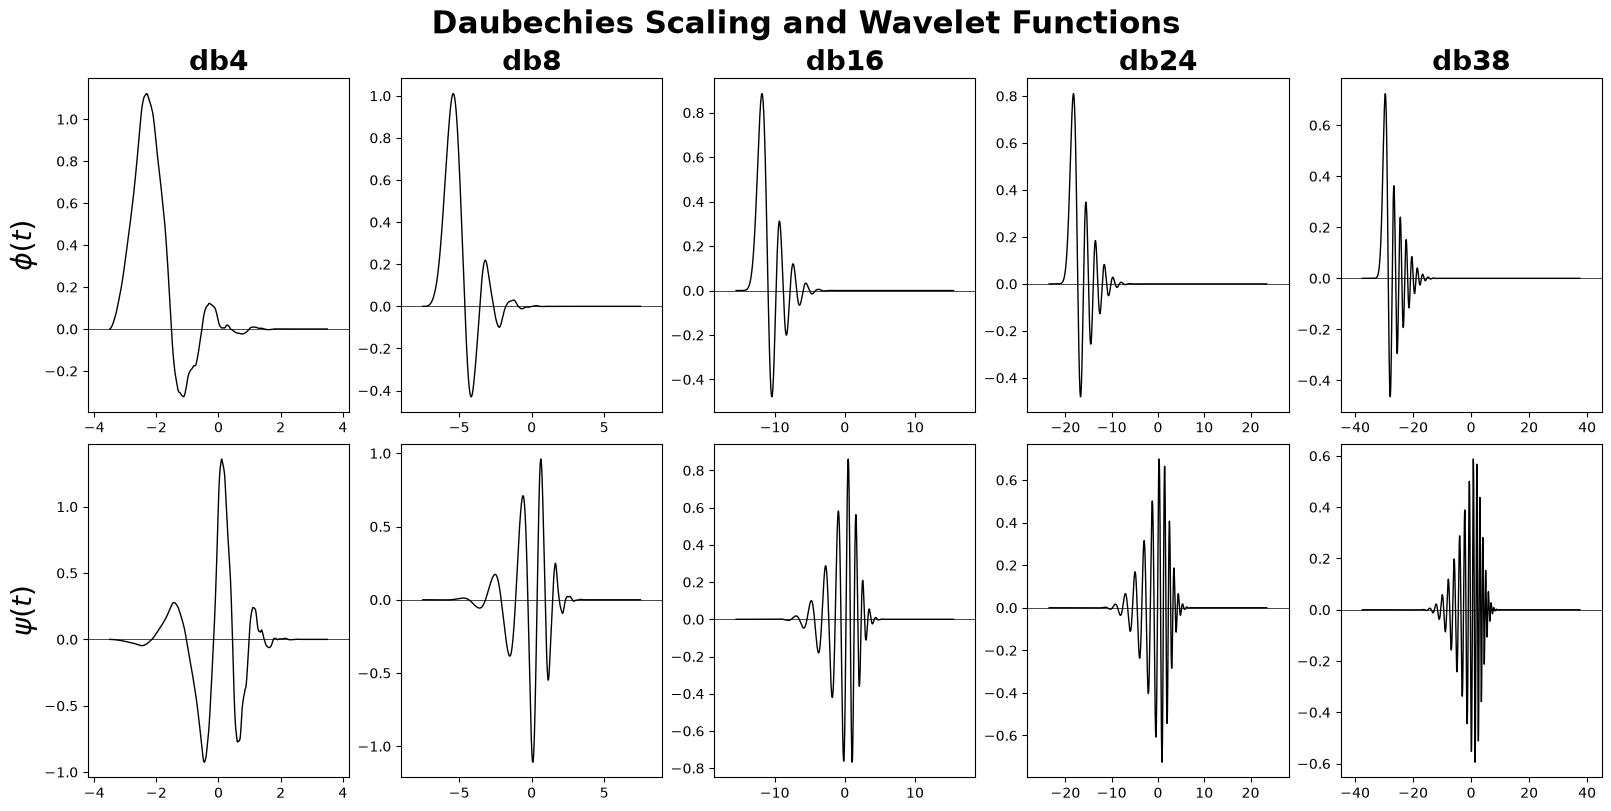

In [14]:
fig, axs = plt.subplots(
    2, 5,
    figsize=(16, 8),
    constrained_layout=True
)

fig.suptitle(
    "Daubechies Scaling and Wavelet Functions",
    fontsize=22,
    fontweight="bold"
)

for i, wavelet in enumerate(WAVELET_FAMILIES):

    w = pywt.Wavelet(wavelet)
    phi, psi, x = w.wavefun(level=8)

    x_centered = x - (x.min() + x.max()) / 2
    support = x_centered.max() - x_centered.min()

    ax = axs[0, i]
    ax.plot(x_centered, phi, color="black", linewidth=1)
    ax.set_title(f"{wavelet}", fontsize=20, fontweight="bold")
    ax.axhline(0, color="black", linewidth=0.5)
    ax.set_xlim(-support * 0.6, support * 0.6)
    ax.set_ylabel(r"$\phi(t)$" if i == 0 else "", fontsize=20)

    ax = axs[1, i]
    ax.plot(x_centered, psi, color="black", linewidth=1)
    ax.axhline(0, color="black", linewidth=0.5)
    ax.set_xlim(-support * 0.6, support * 0.6)
    ax.set_ylabel(r"$\psi(t)$" if i == 0 else "", fontsize=20)

plt.show()

## CNN Feature Maps

In [15]:
def get_cnn_layers(wavelet, node, model_path, audio):
    model = CustomCNN(wavelet, level=3, node=node, pooling="wavelet").to(device)
    model.load_state_dict(torch.load(model_path, map_location=device, weights_only=True))
    model.eval()

    no_of_layers = 0
    conv_layers = []

    model_children = list(model.children())

    for child in model_children:
        if type(child) == nn.Sequential:
            for sub_child in child.children():
                if type(sub_child) == nn.Sequential:
                    for layer in sub_child.children():
                        if type(layer) == nn.Conv1d:
                            no_of_layers += 1
                            conv_layers.append(layer)
                if type(sub_child) == WaveletPooling:
                    no_of_layers += 1
                    conv_layers.append(sub_child)

    results = [conv_layers[0](audio)]
    for i in range(1, len(conv_layers)):
        results.append(conv_layers[i](results[-1]))
    return results

In [16]:
bona_audio = (audios[bonafide.index].astype(np.float32) / 32768).squeeze()
bona_audio = torch.from_numpy(bona_audio).to(device)
bona_audio = bona_audio.unsqueeze(0).unsqueeze(0)
bona_audio.shape

torch.Size([1, 1, 64000])

In [17]:
def plot_feature_heatmap(wavelet, node, outputs):
    activations = {
        "Conv 1": outputs[0][0].detach().cpu().numpy(),
        "Conv 2": outputs[1][0].detach().cpu().numpy(),
        "Wavelet Pooling": outputs[2][0].detach().cpu().numpy(),
        "Conv 3": outputs[3][0].detach().cpu().numpy(),
    }

    norm = TwoSlopeNorm(
        vmin=-0.5,
        vcenter=0,
        vmax=0.5
    )

    fig, axes = plt.subplots(
        len(activations),
        1,
        figsize=(16, 16),
        sharex=False,
        constrained_layout=True
    )


    for ax, (name, signal) in zip(axes, activations.items()):

        im = ax.imshow(
            signal,
            aspect="auto",
            origin="lower",
            interpolation="nearest",
            cmap="viridis",
            norm=norm
        )

        ax.set_title(name, loc="left", fontsize=12)
        ax.set_xlabel("Temporal samples")
        ax.set_ylabel("Channel")

    # Shared colorbar using the last imshow object
    fig.colorbar(
        im,
        ax=axes,
        label="Activation",
        shrink=0.8
    )

    fig.suptitle(
        f"CNN + {wavelet} Wavelet Pooling - Node: {node}",
        fontsize=16
    )

    plt.show()


In [39]:
def get_time_axis(signal, audio_length, sr):
    effective_sr = sr * len(signal) / audio_length
    return np.arange(len(signal)) / effective_sr

def plot_feature_maps(wavelet, node, outputs, audio):
    sr = 16000
    audio = audio.squeeze().detach().cpu().numpy()

    activations = {
        "Conv 1 | Ch 0": outputs[0][0, 0].detach().cpu().numpy(),
        # "Conv 1 | Ch 15": outputs[0][0, 15].detach().cpu().numpy(),

        "Conv 2 | Ch 0": outputs[1][0, 0].detach().cpu().numpy(),
        # "Conv 2 | Ch 15": outputs[1][0, 15].detach().cpu().numpy(),

        "Wavelet Pooling | Ch 0": outputs[2][0, 0].detach().cpu().numpy(),
        # "Wavelet Pooling | Ch 15": outputs[2][0, 15].detach().cpu().numpy(),

        # First convolution after WaveletPooling
        "Conv 3 | Ch 0": outputs[3][0, 0].detach().cpu().numpy(),
        # "Conv 3 | Ch 63": outputs[3][0, 63].detach().cpu().numpy(),
    }

    fig, axes = plt.subplots(
        len(activations) + 1,
        1,
        figsize=(16, 10),
        sharex=True,
        constrained_layout=True
    )

    axes[0].plot(
        np.arange(len(audio)) / sr,
        audio,
        linewidth=0.5,
        color="black"
    )

    axes[0].set_title("Original Audio", loc="left")
    axes[0].set_ylabel("Amplitude")

    for ax, (name, signal) in zip(axes[1:], activations.items()):
        time = get_time_axis(signal, len(audio), sr)

        ax.plot(time, signal, linewidth=0.7)
        ax.set_title(name, loc="left", fontsize=10)
        ax.set_ylabel("Activation")
        ax.grid(alpha=0.2)

    axes[-1].set_xlabel("Time (s)")

    for ax in axes:
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

    fig.suptitle(f"CNN + {wavelet} Wavelet Pooling - Node: {node}")
    plt.show()

Wavelet: db4 - Node: aaa - Bonafide


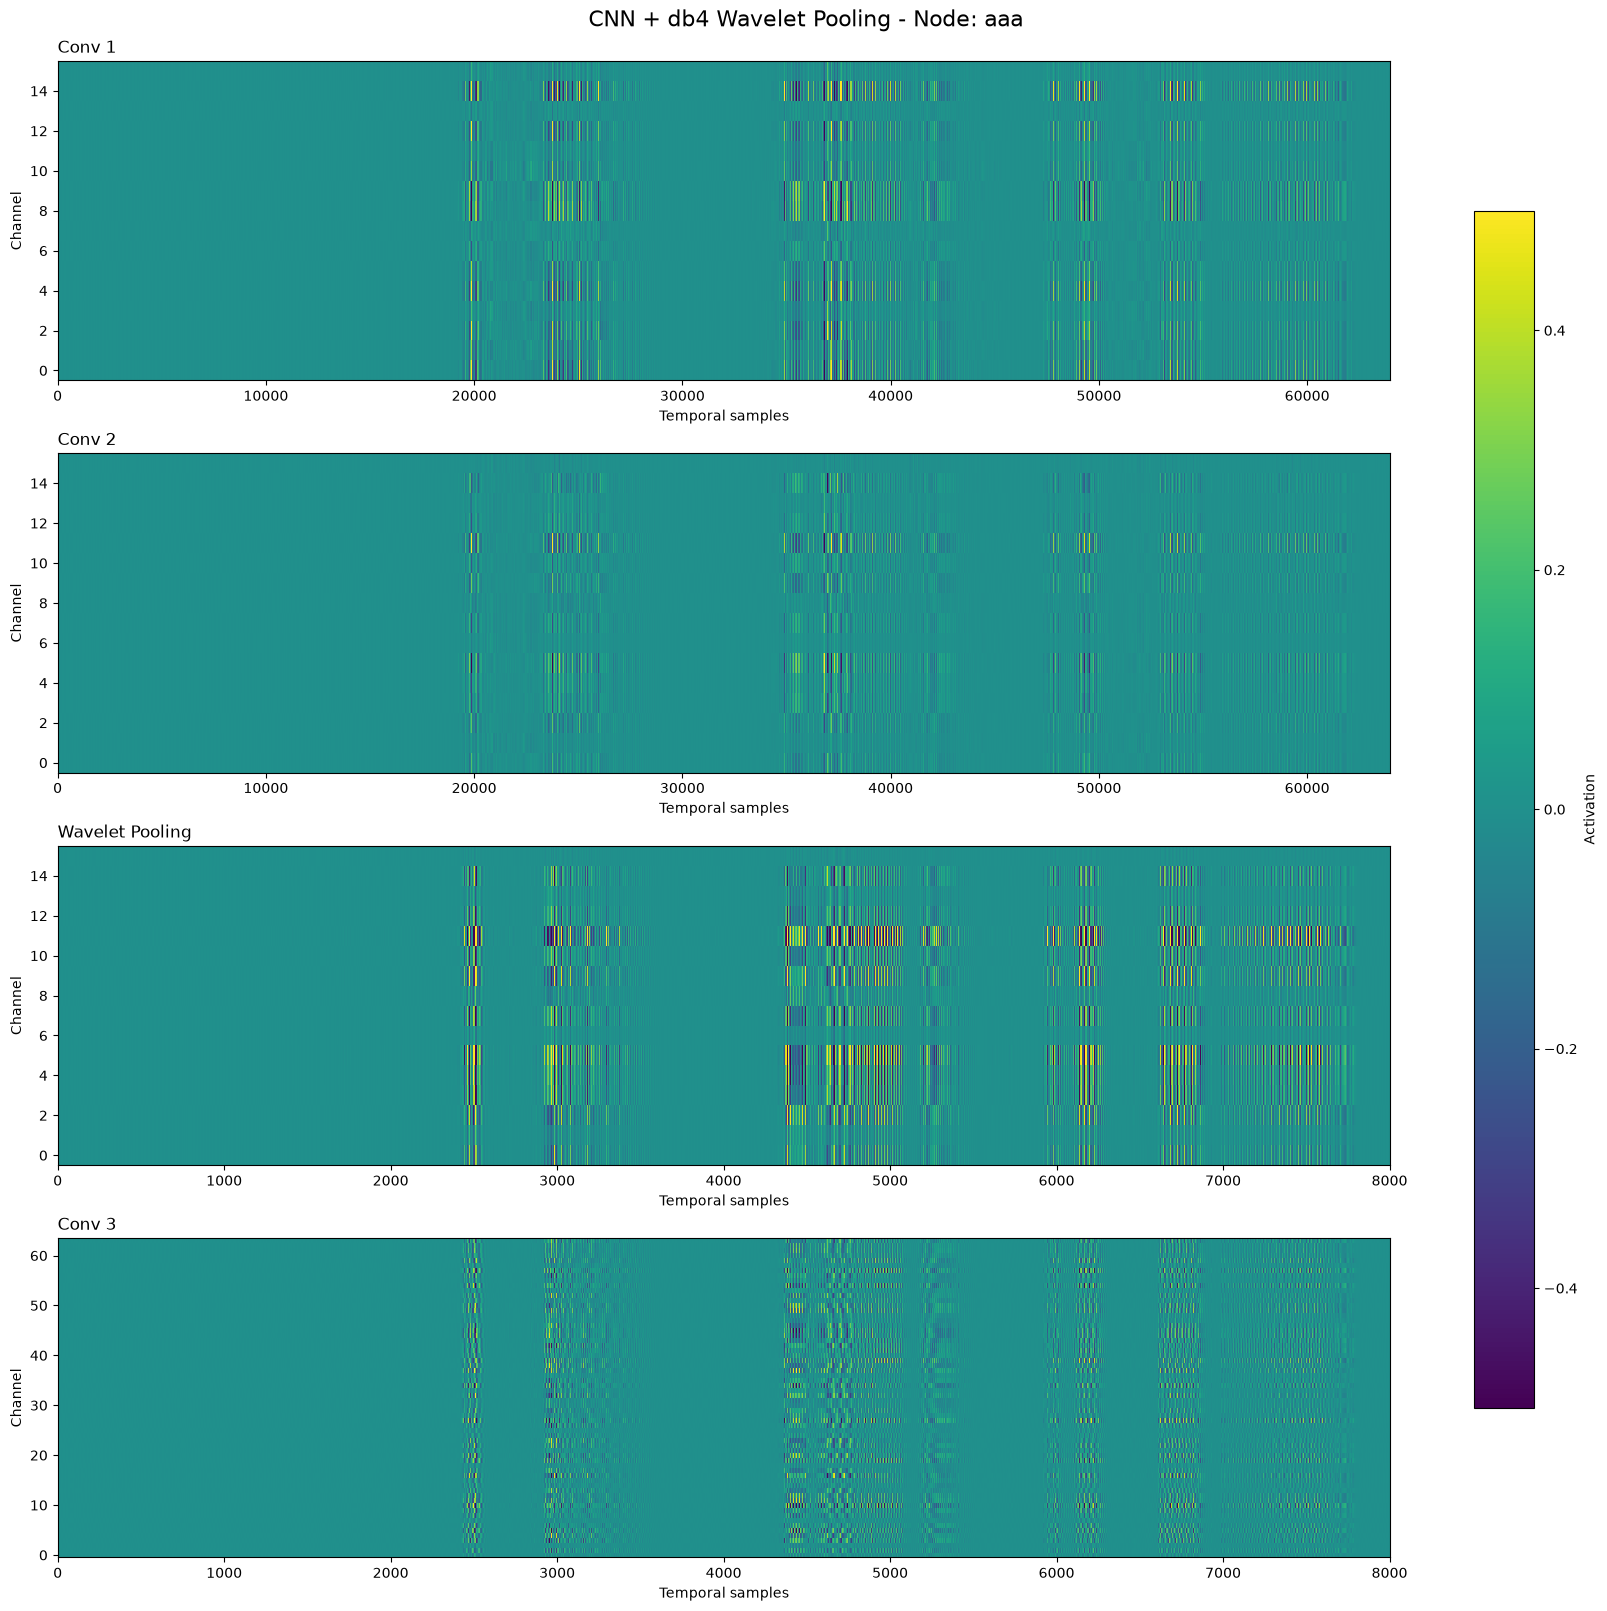

Wavelet: db4 - Node: ddd - Bonafide


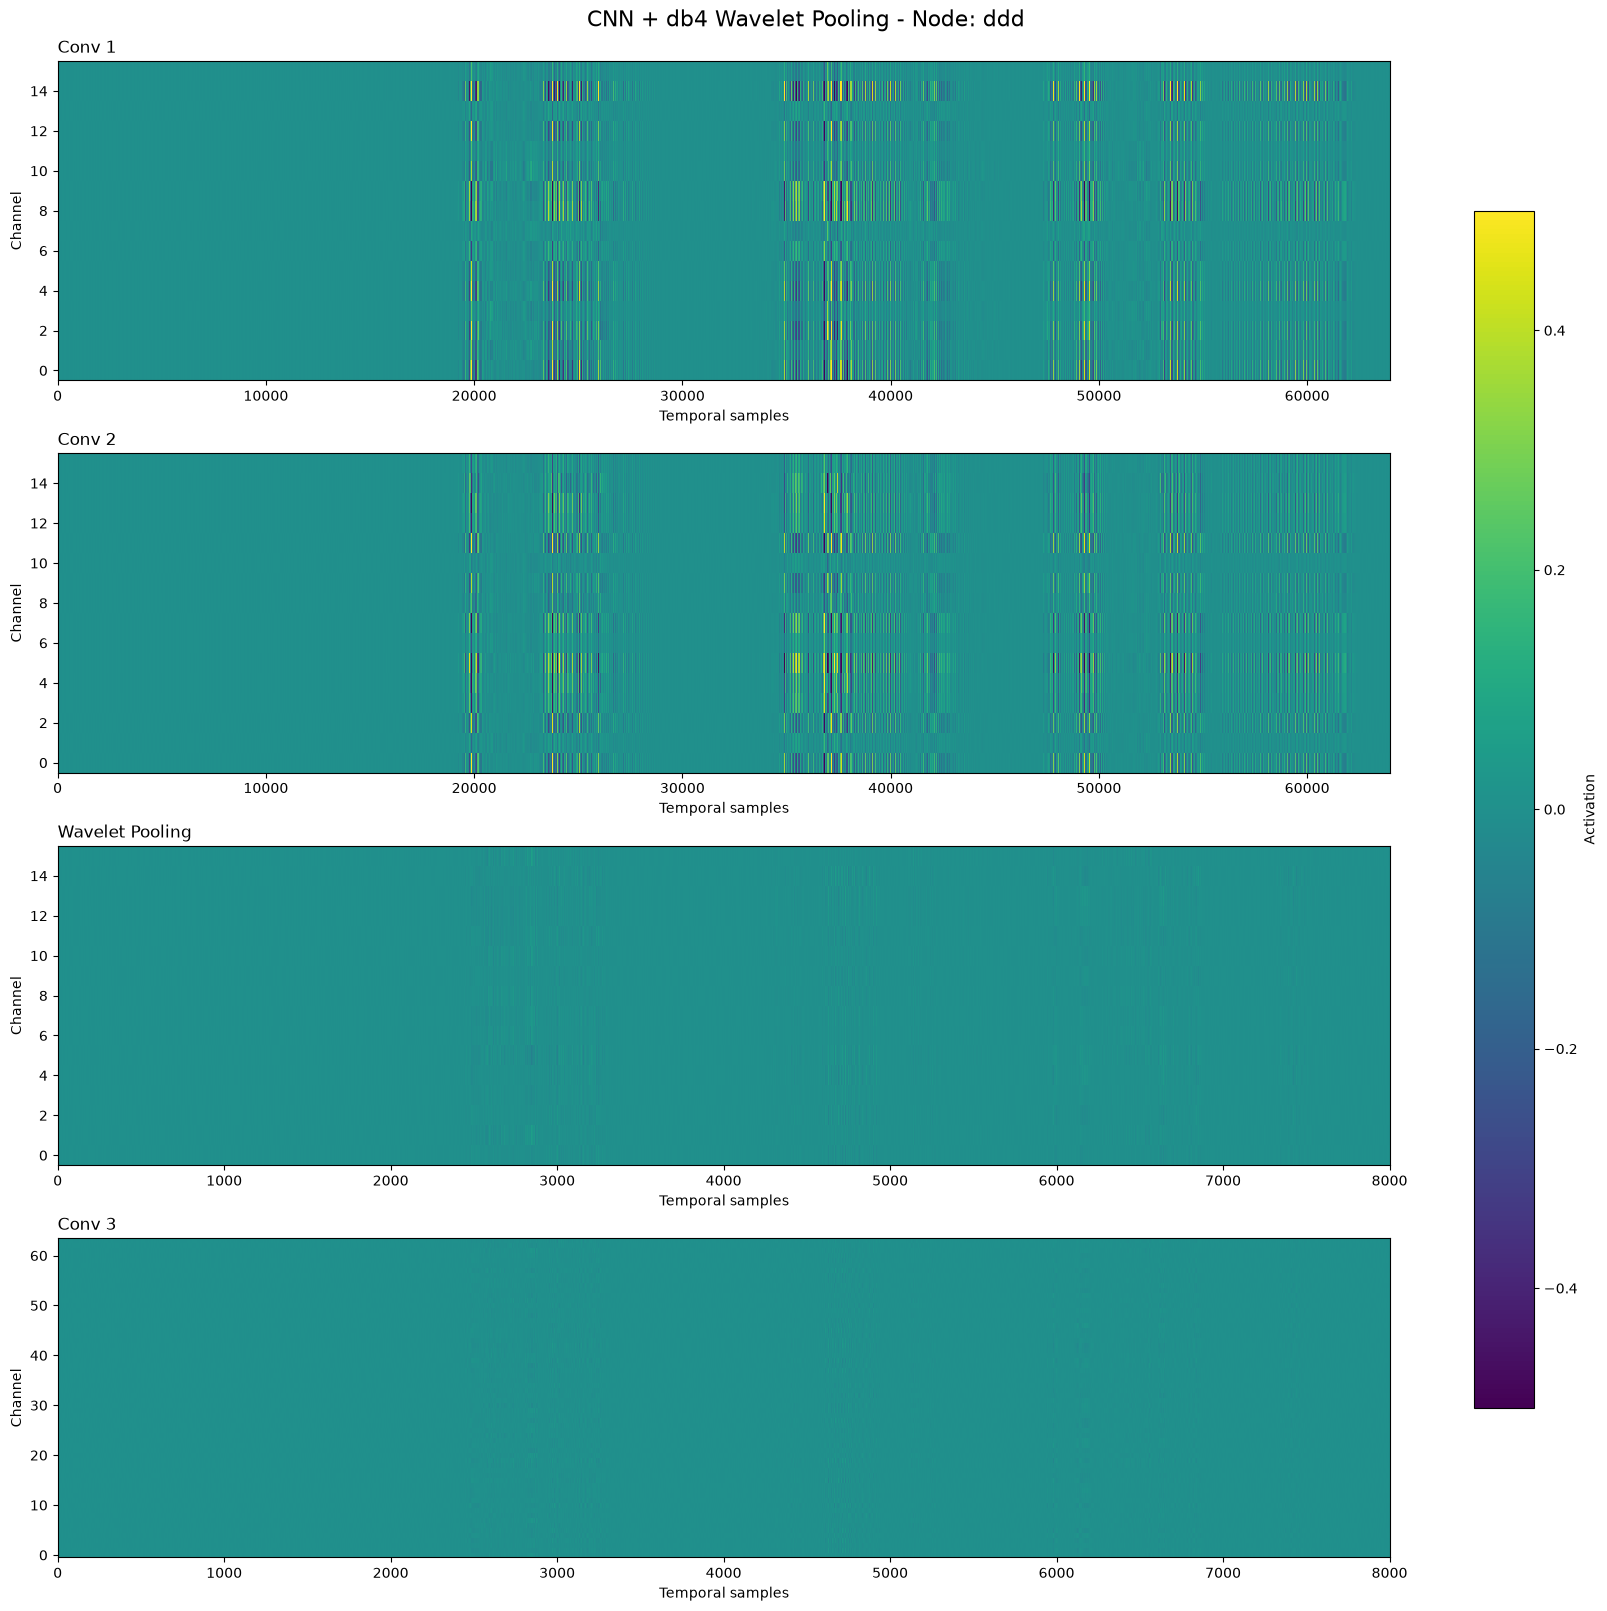

Wavelet: db38 - Node: aaa - Bonafide


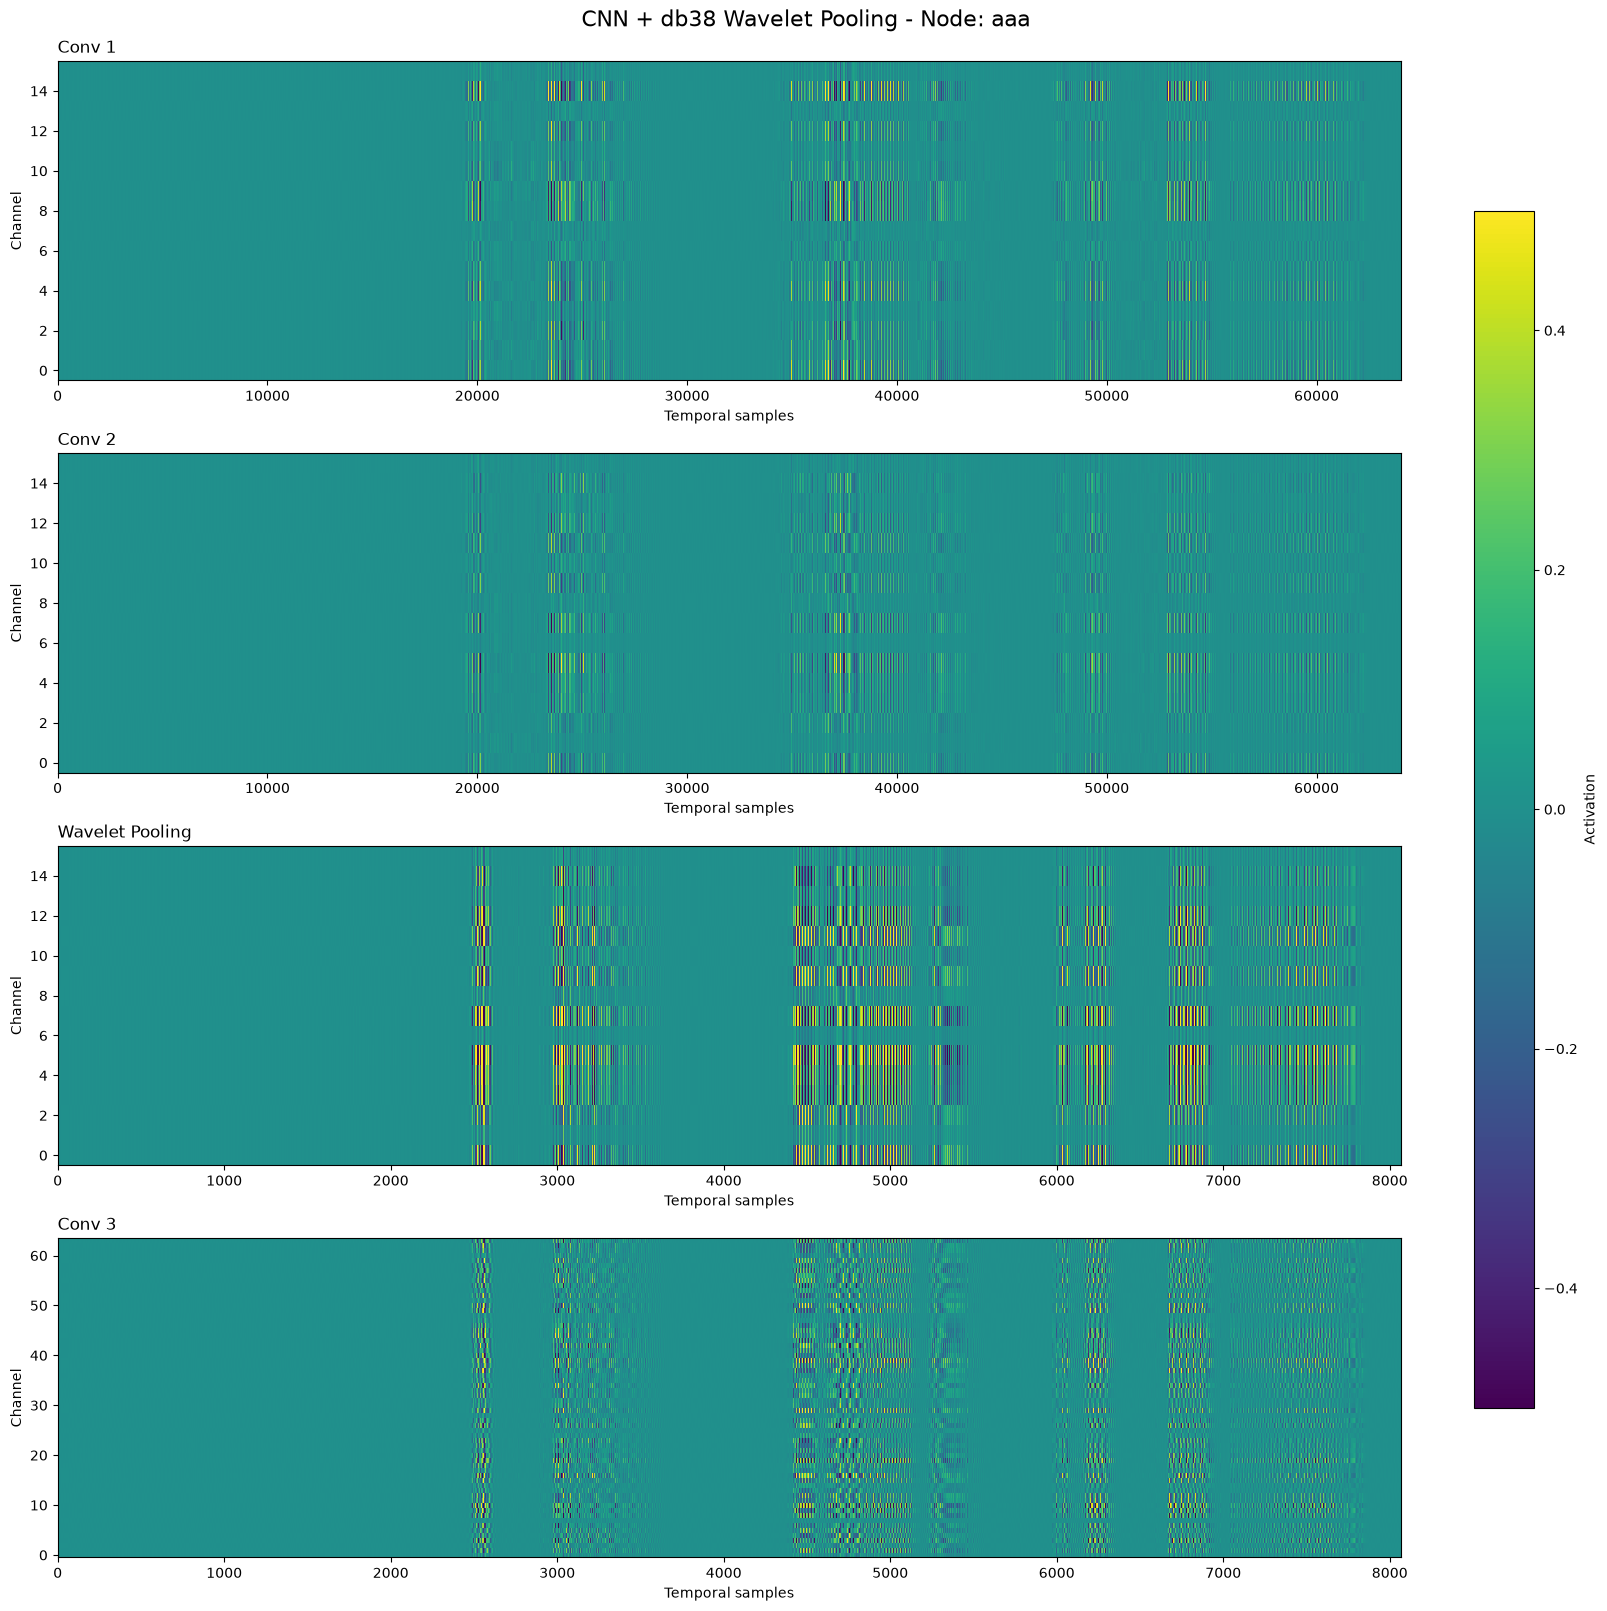

Wavelet: db38 - Node: ddd - Bonafide


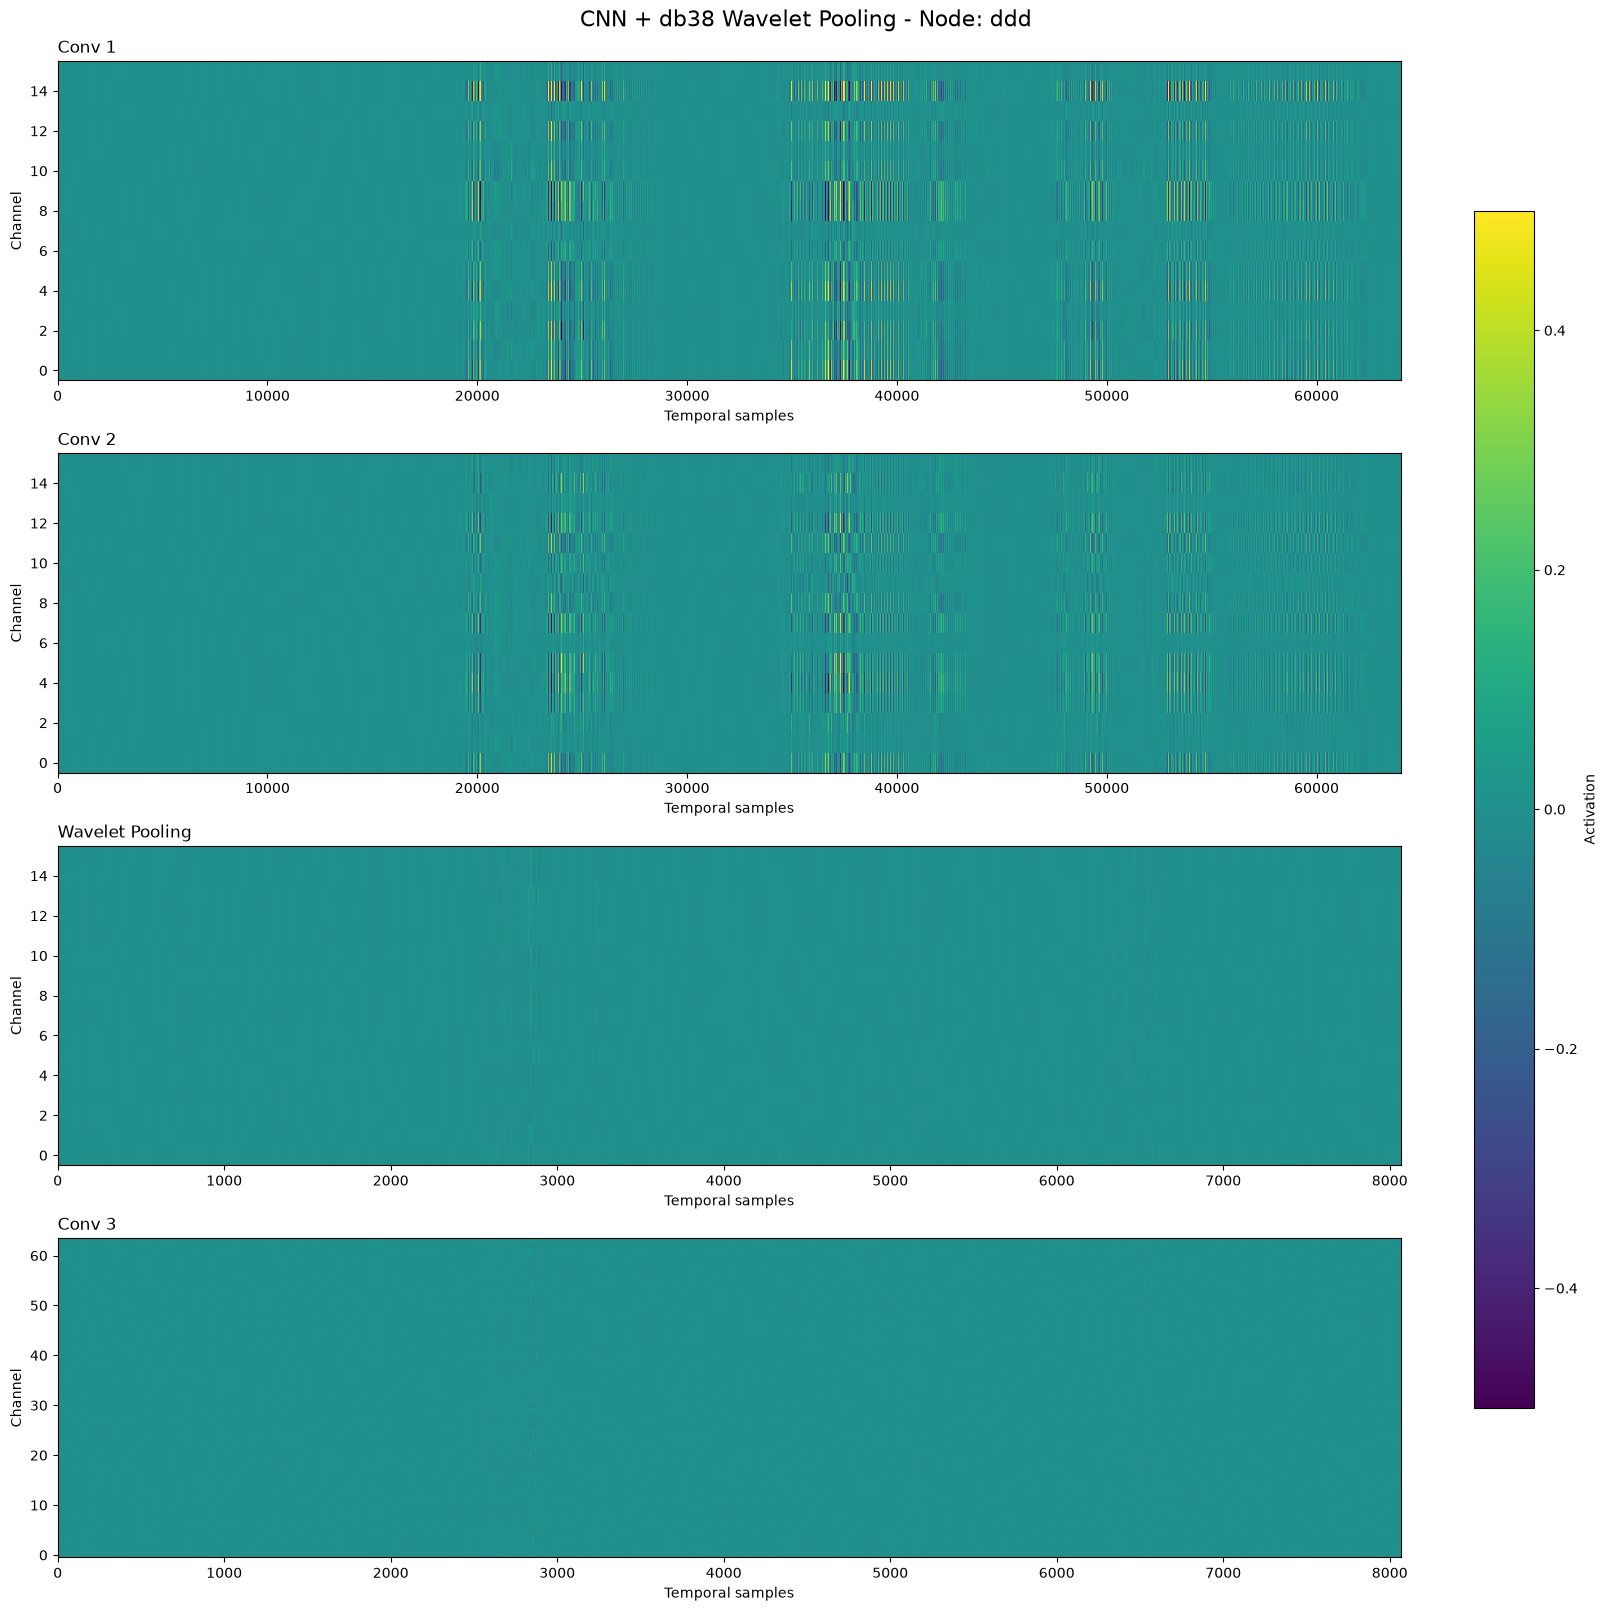

In [33]:
feature_map_wavelets = ["db4", "db38"]
feature_map_nodes = ["aaa", "ddd"]

combinations = itertools.product(feature_map_wavelets, feature_map_nodes, ["wavelet"])

for wavelet, node, pooling in combinations:
    print(f"Wavelet: {wavelet} - Node: {node} - Bonafide")
    model_path = os.path.join(results_dir, "runs", pooling, wavelet, node, f"seed_{seed}", "model.pt")
    outputs = get_cnn_layers(wavelet, node, model_path, bona_audio)
    plot_feature_heatmap(wavelet, node, outputs)

Wavelet: db4 - Node: aaa - Bonafide


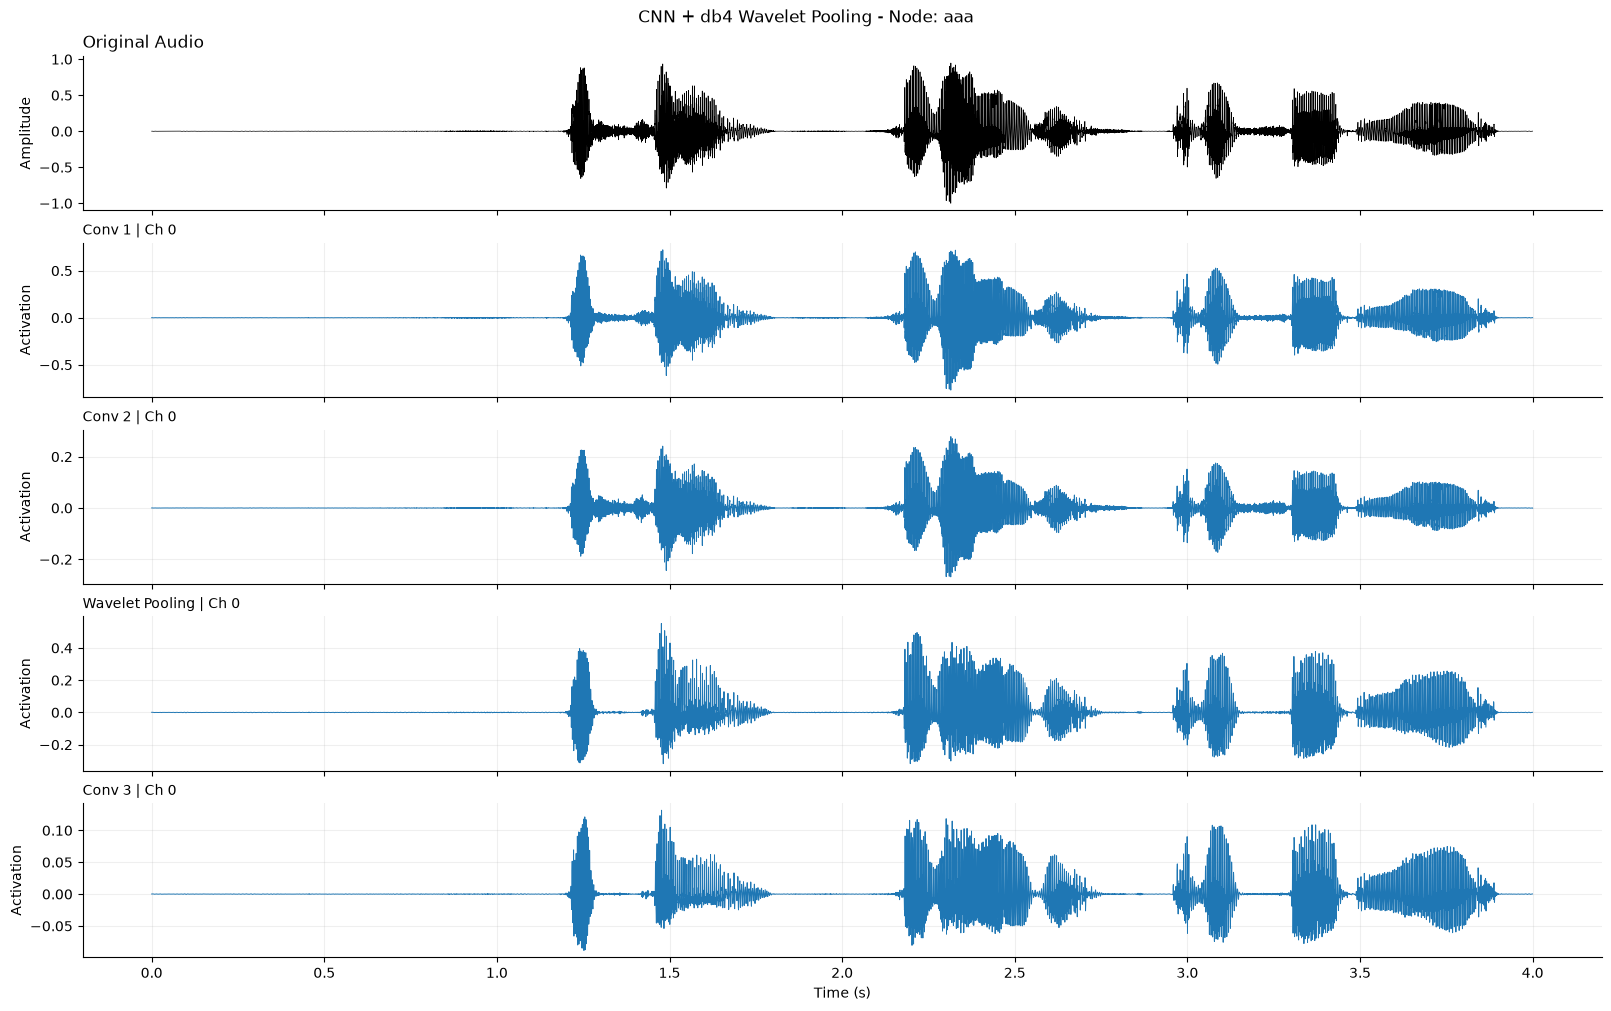

Wavelet: db4 - Node: ddd - Bonafide


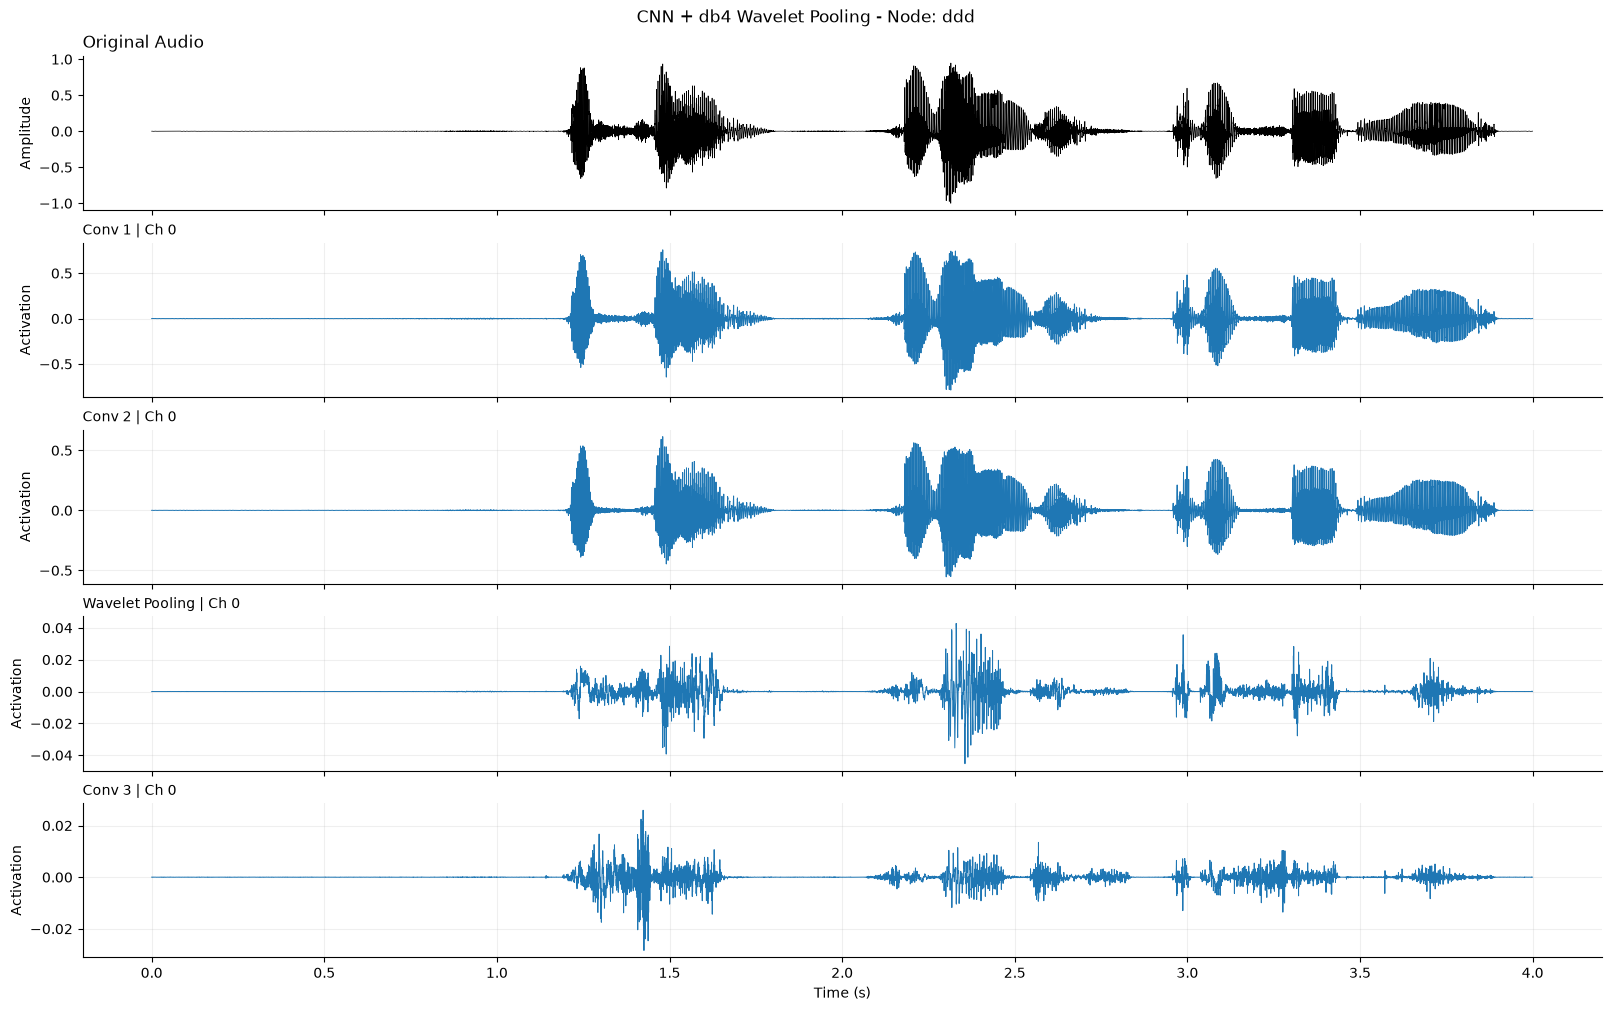

Wavelet: db38 - Node: aaa - Bonafide


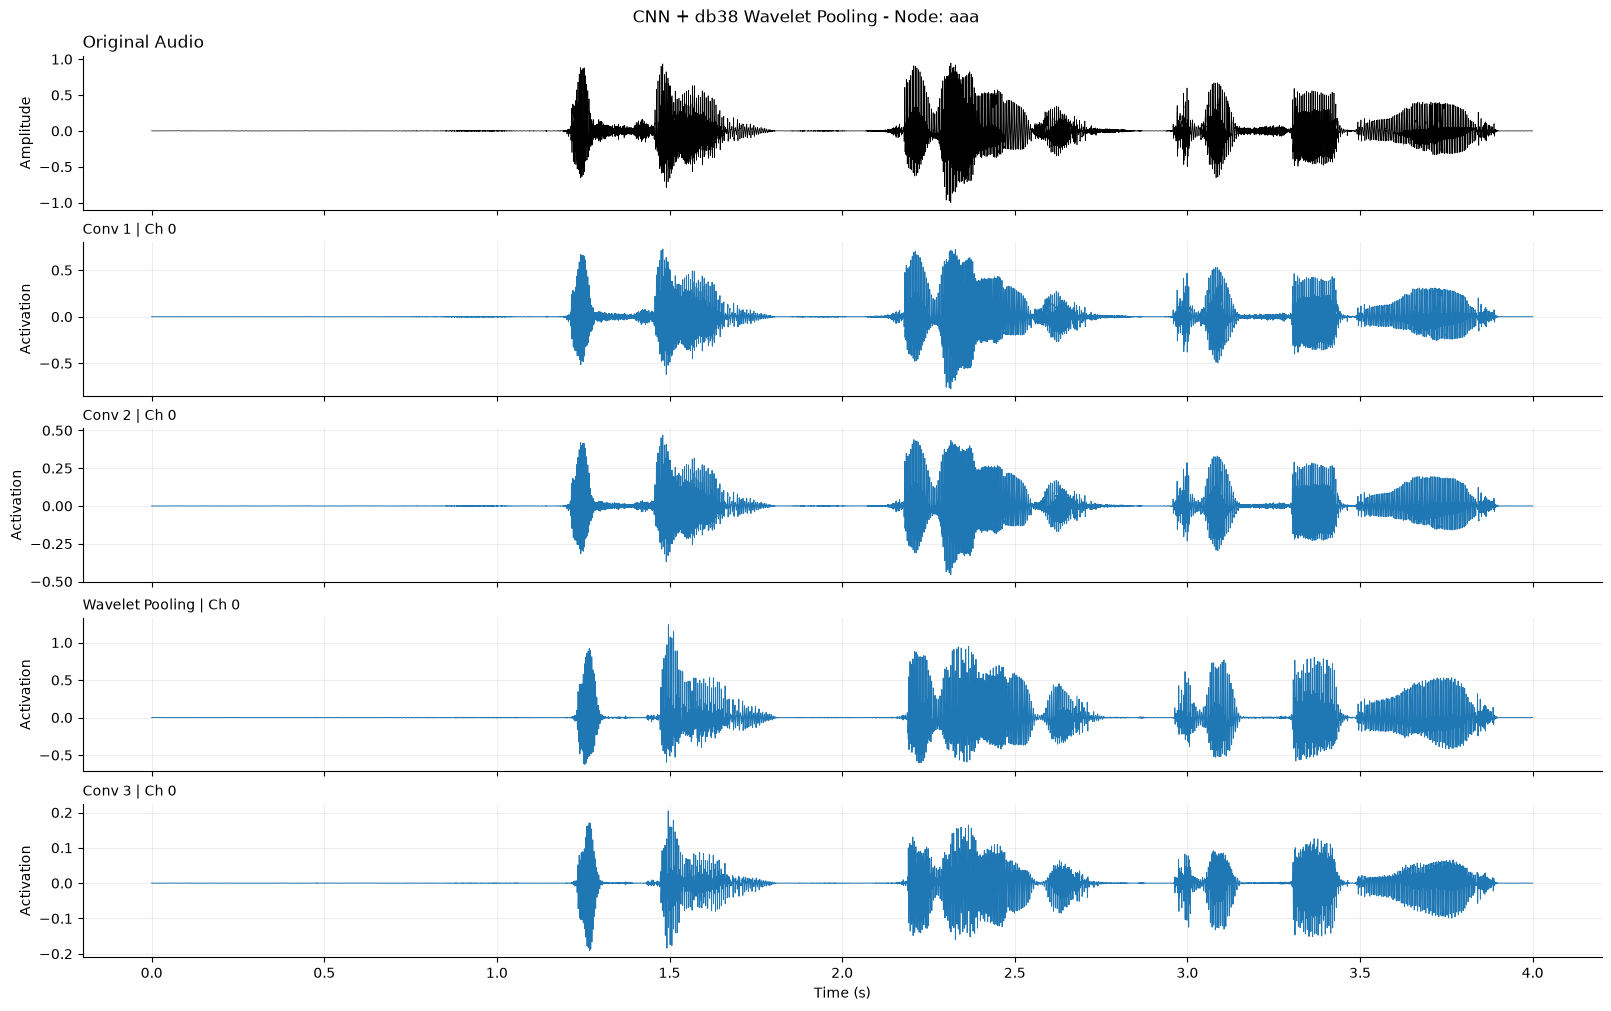

Wavelet: db38 - Node: ddd - Bonafide


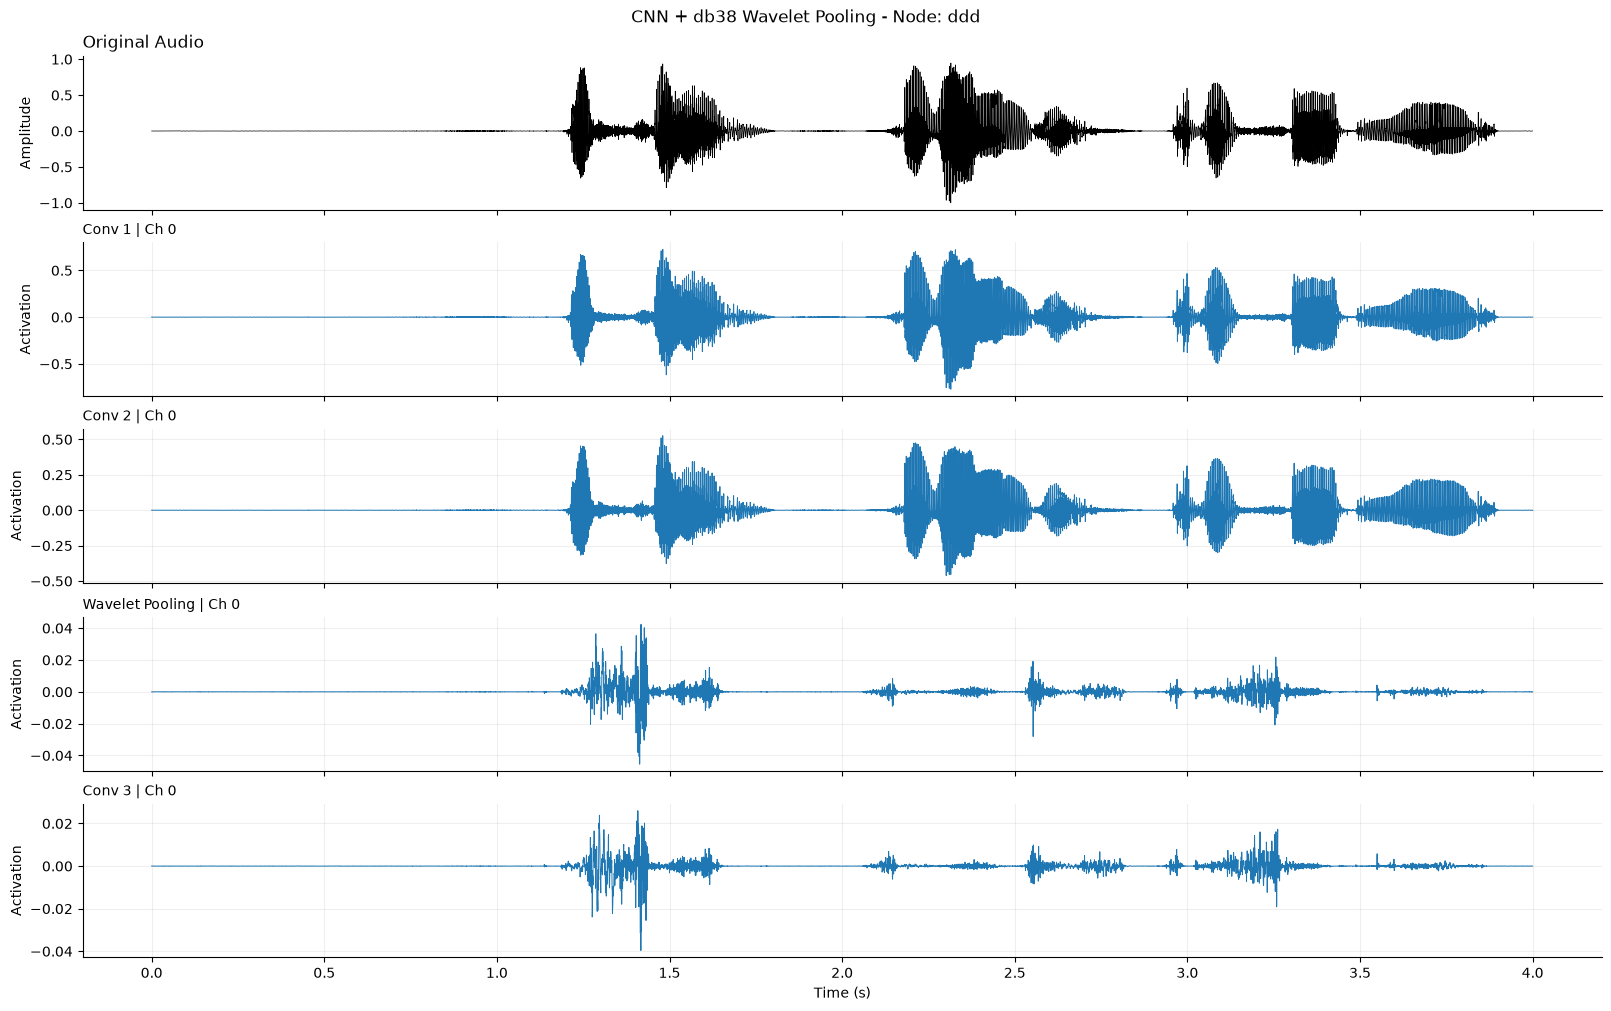

In [40]:
feature_map_wavelets = ["db4", "db38"]
feature_map_nodes = ["aaa", "ddd"]

combinations = itertools.product(feature_map_wavelets, feature_map_nodes, ["wavelet"])

for wavelet, node, pooling in combinations:
    print(f"Wavelet: {wavelet} - Node: {node} - Bonafide")
    model_path = os.path.join(results_dir, "runs", pooling, wavelet, node, f"seed_{seed}", "model.pt")
    outputs = get_cnn_layers(wavelet, node, model_path, bona_audio)
    plot_feature_maps(wavelet, node, outputs, bona_audio)
